# Pulse picking / scan gating: 2p signal at fixed average power

Ex vivo mouse retina. 2 mW at the pupil for every recording, 60 s each.
One position, case0-case4 recorded in place.

In case2-4 the laser is off during the backward scan, so their bs files are a dark recording.

Everything downstream of the cache is a plain array indexed `[position, case]`, so
`signal[i, j]`, `gain[i, j]` etc. can be sliced and printed directly.

In [1]:
from pathlib import Path
import csv
import json
import re
from collections import namedtuple

import cv2
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

DATA = Path("data")
DERIVED = DATA / "derived"   # averaged images and traces (Zenodo)
RAW = DATA / "raw"           # raw videos, only needed to rebuild DERIVED
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

SESSIONS = {s: RAW / s for s in ["2026-09-10", "2026-09-29", "2026-10-09", "2026-10-15"]}

SKIP = ["2026-09-10/left-eye/z-stack"]

CASES = ["case0", "case1", "case2", "case3", "case4"]
LABELS = ["80 MHz\nno gating", "80 MHz\nedge blank", "80 MHz\ngated",
          "40 MHz\ngated", "20 MHz\ngated"]
F_REP = np.array([80.0, 80.0, 80.0, 40.0, 20.0])  # MHz
GATED = [2, 3, 4]   # backward scan blanked -> their bs files are the dark
J_REF = 2           # case2. case0/case1 are too close to the dark to divide by

CLEAN_CH1 = 1.0     # counts of pixel scatter below which a blanked CH1 image is really dark

# Zero offset of the forward scan on top of the backward-scan dark. Measured per configuration
# from the PMT2-OFF controls in the Dark section. This value is only the fallback for a
# configuration without any control recording.
BACKGROUND = 0.31

CASE_COLORS = ["#b6def6",   # case0  no gating      (pale, always drawn with a dark outline)
               "#8ec4f0",   # case1  edge blanking
               "#71a9e6",   # case2  + backward gating
               "#3e68ad",   # case3  + 40 MHz
               "#19154b"]   # case4  + 20 MHz

C_2P = "#006DAD"      # two-photon
C_CONF = "#808781"    # confocal / anything linear in power
C_REF = "tab:red"       # reference lines
C_GUIDE = "0.75"        # guides, identity lines


def save(fig, name, vector=True):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    if vector:

        fig.savefig(FIG / f"{name}.svg", bbox_inches="tight", transparent=True)

## Manuscript figure style

Sizes in mm, font, line widths and output formats for all manuscript figures.

In [2]:
# ==========================================================
# Manuscript figure style
# ==========================================================

MM = 1 / 25.4               # inch per mm
WIDTH_1COL = 89             # mm, single column
WIDTH_2COL = 183            # mm, full page width

PAPER_FONT = "Arial"
PAPER_FONTSIZE = 8          # pt, all text in the figure
PAPER_PANELSIZE = 11         # pt, the panel letters a, b, ...
PAPER_LINEWIDTH = 1.0       # pt, axes, ticks, bar and box edges, reference lines
PAPER_MARKERSIZE = 3        # pt, one dot per position
PAPER_FORMATS = ("pdf", "svg", "png")   # pdf for submission
PAPER_PNG_DPI = 300

PAPER_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": [PAPER_FONT, "Helvetica", "DejaVu Sans"],
    "mathtext.default": "regular",          # superscripts in $...$ use the same font
    "font.size": PAPER_FONTSIZE,
    "axes.titlesize": PAPER_FONTSIZE,
    "axes.labelsize": PAPER_FONTSIZE,
    "xtick.labelsize": PAPER_FONTSIZE,
    "ytick.labelsize": PAPER_FONTSIZE,
    "legend.fontsize": PAPER_FONTSIZE,
    "axes.linewidth": PAPER_LINEWIDTH,
    "xtick.major.width": PAPER_LINEWIDTH,
    "ytick.major.width": PAPER_LINEWIDTH,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "lines.linewidth": PAPER_LINEWIDTH,
    "patch.linewidth": PAPER_LINEWIDTH,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",                 # text stays text in Illustrator / Inkscape
    "pdf.fonttype": 42,                     # embedded TrueType, editable in Illustrator
    "figure.dpi": 150,
}


def paper_style():
    """Use as `with paper_style():` around everything that builds and saves a manuscript figure."""
    return plt.rc_context(PAPER_RC)


def panel_label(ax, letter, dx=-28, dy=4):
    """Bold lower-case letter at the top left of a panel. dx, dy in points from the axes corner."""
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(dx, dy),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=PAPER_PANELSIZE, fontweight="bold")


def save_paper(fig, name):
    """Save at exactly the size the figure was made with (no tight bbox, so widths stay in mm)."""
    for ext in PAPER_FORMATS:
        fig.savefig(FIG / f"{name}.{ext}", dpi=PAPER_PNG_DPI if ext == "png" else None)
    print("saved", ", ".join(f"{name}.{ext}" for ext in PAPER_FORMATS))

## Videos -> tif

One pass per video: mean image, per-frame mean, fraction of pixels stuck at 255. Written to
`derived/<session>/<position>/`, so the raw drive is only needed the first time a session is
added. Each session also gets a `meta.json` (pixel size, fps, dead columns) and a
`recordings.csv` (start time of every recording).

In [3]:
def read_header(csv_path):
    head = {}
    for line in Path(csv_path).read_text().splitlines():
        if "," not in line:
            continue
        k, v = line.split(",", 1)
        if k.strip().isdigit():
            break
        try:
            head[k.strip()] = float(v)
        except ValueError:
            pass
    return head


def start_time(csv_path):
    """Session clock in seconds at the first frame (3rd column of the frame block)."""
    for line in Path(csv_path).read_text().splitlines():
        p = line.split(",")
        if len(p) == 3 and p[0].strip().isdigit():
            return float(p[2])
    return np.nan


def dead_columns(avi, n=30):
    """Sinusoidal rectification leaves zero columns at both edges. Find the valid range."""
    cap = cv2.VideoCapture(str(avi))
    acc = None
    for _ in range(n):
        ok, f = cap.read()
        if not ok:
            break
        g = f[:, :, 0].astype(np.float64)
        acc = g if acc is None else acc + g
    cap.release()
    nz = np.nonzero(acc.mean(0) > 0)[0]
    return int(nz.min()), int(nz.max()) + 1


def video_stats(avi, x0, x1):
    """One pass over an avi. Returns mean image, per-frame mean, clipped fraction."""
    cap = cv2.VideoCapture(str(avi))
    total, n, trace, clipped = None, 0, [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        f = frame[:, x0:x1, 0].astype(np.float64)
        total = f.copy() if total is None else total + f
        trace.append(f.mean())
        clipped += int((f >= 255).sum())
        n += 1
    cap.release()
    return (total / n).astype(np.float32), np.array(trace), clipped / (n * f.size)


def split_stem(stem):
    """Sort a filename stem into (case, kind).

        case0           -> ("case0", "normal")    the thing being measured
        case4_repeat    -> ("case4", "repeat")    same config again later in the session
        case4_2         -> ("case4", "repeat")
        case0_ch2_OFF   -> ("case0", "control")   PMT2 switched off: no light can be detected
        LASER_OFF       -> (""     , "control")   laser off: no light exists

    Controls are cached and indexed, but kept out of the signal analysis. Without this a
    `_ch2_OFF` file parses as a repeat of its case and lands in the bleaching statistics.
    """
    parts = stem.split("_")
    if "OFF" in parts:
        return (parts[0] if parts[0] in CASES else ""), "control"
    return parts[0], ("repeat" if len(parts) > 1 else "normal")


def build_cache(name, root, rebuild=False):
    out = DERIVED / name
    out.mkdir(parents=True, exist_ok=True)

    if not (out / "meta.json").exists() or rebuild:
        h = read_header(next(root.glob("**/*_0001.csv")))
        x0, x1 = dead_columns(next(root.glob("**/*_CH1_fs_0001.avi")))
        (out / "meta.json").write_text(json.dumps(
            dict(px_um=h["Fast scan FOV"] / h["Linear Width"],
                 py_um=h["Slow scan FOV"] / h["Slow scan forward lines"],
                 fps=h["Frequency of the slow scanner"], x0=x0, x1=x1), indent=2))
    meta = json.loads((out / "meta.json").read_text())

    rows = []
    # the index is usually _0001 but not always: a repeated save gives _0002 and so on
    for csv_path in sorted(root.glob("**/*.csv")):
        m = re.fullmatch(r"(.+)_(\d{4})\.csv", csv_path.name)
        if m is None:
            continue
        stem, index = m.groups()
        case, kind = split_stem(stem)
        if case not in CASES and kind != "control":
            continue
        pos = csv_path.parent.relative_to(root).as_posix()
        rows.append([f"{name}/{pos}", pos, case, kind, stem, start_time(csv_path)])
        for avi in sorted(csv_path.parent.glob(f"{stem}_CH*_{index}.avi")):
            dest = out / pos / avi.name.replace(f"_{index}.avi", "")
            if Path(f"{dest}_avg.tif").exists():
                continue
            dest.parent.mkdir(parents=True, exist_ok=True)
            mean, trace, clip = video_stats(avi, meta["x0"], meta["x1"])
            tifffile.imwrite(f"{dest}_avg.tif", mean, imagej=True,
                             resolution=(1 / meta["px_um"], 1 / meta["py_um"]),
                             metadata={"unit": "um"})
            np.savez(dest.with_suffix(".npz"), trace=trace, clip_frac=clip)
            print(f"{name}/{pos} {avi.name}")

    with open(out / "recordings.csv", "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["site", "position", "case", "kind", "stem", "t0"])
        w.writerows(rows)


for session, root in SESSIONS.items():
    if not (DERIVED / session / "recordings.csv").exists():
        build_cache(session, root)

## Recording index

One `Rec` per recording. `case` is the index into `CASES`, not the string, so it can be used
directly as a column index further down.

In [4]:
Rec = namedtuple("Rec", "site session case is_repeat stem t0")
Ctl = namedtuple("Ctl", "site session case stem t0")   # PMT2 off / laser off

META = {s: json.loads((DERIVED / s / "meta.json").read_text()) for s in SESSIONS}

INDEX, CONTROLS = [], []
for session in SESSIONS:
    with open(DERIVED / session / "recordings.csv", newline="") as fh:
        for row in csv.DictReader(fh):
            if row["site"] in SKIP:
                continue
            if row["kind"] == "control":
                CONTROLS.append(Ctl(row["site"], session, row["case"], row["stem"],
                                    float(row["t0"])))
            elif row["case"] in CASES:
                INDEX.append(Rec(row["site"], session, CASES.index(row["case"]),
                                 row["kind"] == "repeat", row["stem"], float(row["t0"])))

SITES = sorted({r.site for r in INDEX})
N_SITE, N_CASE = len(SITES), len(CASES)


def find(site, case, is_repeat=False):
    """The recording at this position for this case, or None if it was not taken."""
    for r in INDEX:
        if r.site == site and r.case == case and r.is_repeat == is_repeat:
            return r
    return None


def px_um(site):
    return META[site.split("/")[0]]["px_um"]


def fps(site):
    return META[site.split("/")[0]]["fps"]


def read_image(site, stem, ch="CH2", scan="fs"):
    return tifffile.imread(DERIVED / site / f"{stem}_{ch}_{scan}_avg.tif")[40:,40:]


def read_trace(site, stem, ch="CH2", scan="fs"):
    return np.load(DERIVED / site / f"{stem}_{ch}_{scan}.npz")["trace"]


def read_clip(site, stem, ch="CH2", scan="fs"):
    return float(np.load(DERIVED / site / f"{stem}_{ch}_{scan}.npz")["clip_frac"])


def control(site, case=None, stem=None):
    """A control recording at this position, or None. `case` picks the matching PMT2-off run,
    stem=\"LASER_OFF\" picks the laser-off run."""
    for c in CONTROLS:
        if c.site != site:
            continue
        if stem is not None and c.stem == stem:
            return c
        if case is not None and c.case == CASES[case] and stem is None:
            return c
    return None


print(f"{len(INDEX)} recordings, {N_SITE} positions, {len(CONTROLS)} controls")
for session in SESSIONS:
    print(f"  {session}  {sum(r.session == session for r in INDEX):2d} recordings"
          f"  {sum(c.session == session for c in CONTROLS):2d} controls")
if CONTROLS:
    print("\ncontrols found:")
    for c in CONTROLS:
        print(f"  {c.site:<22} {c.stem}")

99 recordings, 18 positions, 12 controls
  2026-09-10  20 recordings   0 controls
  2026-09-29  38 recordings   0 controls
  2026-10-09  29 recordings   0 controls
  2026-10-15  12 recordings  12 controls

controls found:
  2026-10-15/1           case0_ch2_OFF
  2026-10-15/1           case1_ch2_OFF
  2026-10-15/1           case2_ch2_OFF
  2026-10-15/1           case3_ch2_OFF
  2026-10-15/1           case4_ch2_OFF
  2026-10-15/1           LASER_OFF
  2026-10-15/2           case0_ch2_OFF
  2026-10-15/2           case1_ch2_OFF
  2026-10-15/2           case2_ch2_OFF
  2026-10-15/2           case3_ch2_OFF
  2026-10-15/2           case4_ch2_OFF
  2026-10-15/2           LASER_OFF


## Recording order

From frame timestamps in the csv files. The sequence was alternated between positions so that
bleaching is not confounded with the case number. `(r)` = repeat

In [5]:
for site in SITES:
    here = sorted((r for r in INDEX if r.site == site), key=lambda r: r.t0)
    names = " -> ".join(CASES[r.case] + (" (r)" if r.is_repeat else "") for r in here)
    span = (here[-1].t0 - here[0].t0) / 60
    print(f"{site:<22} {span:5.1f} min   {names}")

2026-09-10/left-eye/1   13.1 min   case3 -> case4 -> case2 -> case1 -> case0
2026-09-10/left-eye/2   12.1 min   case0 -> case1 -> case2 -> case3 -> case4
2026-09-10/left-eye/3   11.4 min   case4 -> case3 -> case2 -> case1 -> case0
2026-09-10/left-eye/4   12.4 min   case0 -> case1 -> case2 -> case3 -> case4
2026-09-29/1            11.5 min   case4 -> case3 -> case2 -> case1 -> case0
2026-09-29/2            13.6 min   case0 -> case1 -> case2 -> case3 -> case4
2026-09-29/3             9.7 min   case4 -> case3 -> case2 -> case1 -> case0
2026-09-29/4            11.0 min   case0 -> case1 -> case2 -> case3 -> case4
2026-09-29/5            14.9 min   case4 -> case3 -> case2 -> case1 -> case0 -> case4 (r)
2026-09-29/6            20.1 min   case4 -> case3 -> case2 -> case1 -> case0 -> case4 (r)
2026-09-29/7            14.3 min   case4 -> case3 -> case2 -> case1 -> case0 -> case4 (r)
2026-10-09/1            16.1 min   case4 -> case3 -> case2 -> case1 -> case0 -> case4 (r)
2026-10-09/2            

## Supplementary Fig. 3

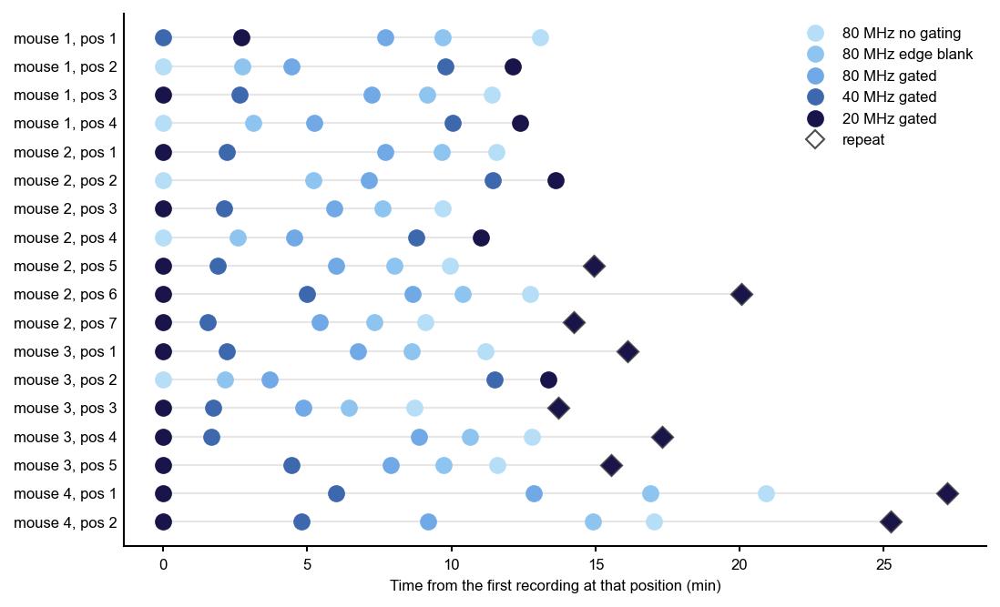

saved recording_order.pdf, recording_order.svg, recording_order.png


In [6]:
with paper_style():    
    fig, ax = plt.subplots(figsize=(WIDTH_2COL * MM, 110 * MM), layout="constrained")

    for y, site in enumerate(SITES):
        here = sorted((r for r in INDEX if r.site == site), key=lambda r: r.t0)
        t = [(r.t0 - here[0].t0) / 60 for r in here]
        ax.plot(t, [y] * len(t), "-", color="0.9", lw=1, zorder=1)
        for ti, r in zip(t, here):
            ax.plot(ti, y, "D" if r.is_repeat else "o", ms=8 if r.is_repeat else 9,
                    color=CASE_COLORS[r.case], mec="0.3" if r.is_repeat else "none",
                    mew=0.7, zorder=3)

    ax.set_yticks(range(N_SITE))
    ax.set_yticklabels([s.replace("2026-09-10/left-eye/", "mouse 1, pos ")
                        .replace("2026-09-29/", "mouse 2, pos ")
                        .replace("2026-10-09/", "mouse 3, pos ")
                        .replace("2026-10-15/", "mouse 4, pos ")  for s in SITES])
    ax.invert_yaxis()
    ax.set_xlabel("Time from the first recording at that position (min)")
    ax.tick_params(axis="y", length=0)

    handles = [plt.Line2D([], [], marker="o", ls="", ms=8, color=CASE_COLORS[j],
                        label=LABELS[j].replace("\n", " ")) for j in range(N_CASE)]
    handles.append(plt.Line2D([], [], marker="D", ls="", ms=7, color="w", mec="0.3", label="repeat"))
    ax.legend(handles=handles, frameon=False, ncol=1, loc="upper right", labelspacing=0.5)#,
            #bbox_to_anchor=(0.5, 1.0), handletextpad=0.3, columnspacing=1.2)
    plt.show()
    save_paper(fig, "recording_order")
save(fig, "fig0_order")

## Dark signal

case2-4 blank the laser during the backward scan, so their bs files are a dark recording taken at
the same time as the signal. Average them per position and subtract.

The CH2 dark is ~2 counts and the case0 signal is ~0.1, so this is not a small correction.
`ch2_noise` is the pixel-to-pixel scatter of the dark image after averaging the full 60 s, i.e.
the noise floor of one averaged image.

`leak` flags positions where the blanked backward scan is not actually dark in CH1. That happens
while the Pockels cell is still warming up, its extinction is incomplete and a few % of light gets
through. Only the confocal notices; the 2p channel is untouched because the leak enters squared.
For those positions the CH1 dark is taken from the clean positions of the same session instead.

In [7]:
def blank_stats(site, stem, ch):
    """Mean and pixel-to-pixel scatter of one blanked backward-scan image."""
    im = read_image(site, stem, ch, "bs")
    return float(im.mean()), float(im.std())


# case0/case1 never blank, their backward scan still has light in it,
# so they use the dark of case2.
ch2_dark = np.full((N_SITE, N_CASE), np.nan)
ch2_noise = np.full((N_SITE, N_CASE), np.nan)

for i, site in enumerate(SITES):
    for j in GATED:
        r = find(site, j)
        if r is not None:
            ch2_dark[i, j], ch2_noise[i, j] = blank_stats(site, r.stem, "CH2")
    # case0/case1 never blank the backward scan, so they have no dark of their own and borrow the
    # one of case2. Their zero offset further down is measured relative to that same dark, which
    # takes care of the configuration-dependent baseline of the electronics.
    for j in range(N_CASE):
        if np.isnan(ch2_dark[i, j]):
            ch2_dark[i, j] = ch2_dark[i, J_REF]
            ch2_noise[i, j] = ch2_noise[i, J_REF]


def dark_of(site, stem, case):
    """Dark and noise for any single recording, repeats included."""
    if case in GATED:
        return blank_stats(site, stem, "CH2")
    i = SITES.index(site)
    return float(ch2_dark[i, case]), float(ch2_noise[i, case])


# CH1 keeps one dark per session. Its blanked frames pick up leak-through whenever the Pockels
# extinction is still settling, so a per-case CH1 dark would follow the leak rather than the dark.
ch1_blank = np.zeros(N_SITE)
ch1_scatter = np.zeros(N_SITE)
for i, site in enumerate(SITES):
    v = [blank_stats(site, find(site, j).stem, "CH1") for j in GATED if find(site, j)]
    ch1_blank[i] = np.mean([x[0] for x in v])
    ch1_scatter[i] = np.mean([x[1] for x in v])

leak = ch1_scatter >= CLEAN_CH1

ch1_dark = np.zeros(N_SITE)
for session in SESSIONS:
    here = np.array([s.startswith(session) for s in SITES])
    clean = here & ~leak
    if not clean.any():
        clean = here & (ch1_blank == ch1_blank[here].min())
    ch1_dark[here] = np.median(ch1_blank[clean])

DARK_FROM = {j: (j if j in GATED else J_REF) for j in range(N_CASE)}   # whose backward scan is the dark

def controls_of(site, case):
    return [c for c in CONTROLS if c.site == site and c.case == CASES[case]]


offset_meas = np.full((N_SITE, N_CASE), np.nan)
for i, site in enumerate(SITES):
    for j in range(N_CASE):
        fs_j = [read_image(site, c.stem, "CH2", "fs").mean() for c in controls_of(site, j)]
        bs_k = [read_image(site, c.stem, "CH2", "bs").mean() for c in controls_of(site, DARK_FROM[j])]
        if fs_j and bs_k:
            offset_meas[i, j] = np.mean(fs_j) - np.mean(bs_k)

has_control = ~np.isnan(offset_meas).all(axis=1)
OFFSET_PER_CASE = np.array([np.nanmean(offset_meas[:, j]) if (~np.isnan(offset_meas[:, j])).any()
                            else BACKGROUND for j in range(N_CASE)])
offset = np.where(np.isnan(offset_meas), OFFSET_PER_CASE[None, :], offset_meas)

print("CH2 dark, one per case (case0/case1 use the dark of case2)\n")
print(f"{'position':<22}" + "".join(f"{c:>9}" for c in CASES) + f"{'ch1 dark':>10}{'leak':>6}")
for i, site in enumerate(SITES):
    print(f"{site:<22}" + "".join(f"{ch2_dark[i, j]:9.3f}" for j in range(N_CASE))
          + f"{ch1_dark[i]:10.2f}{str(leak[i]):>6}")

print("\nzero offset on top of the dark (forward scan without light minus the dark used for that case)\n")
print(f"{'position':<22}{'source':>10}" + "".join(f"{c:>9}" for c in CASES))
for i, site in enumerate(SITES):
    print(f"{site:<22}{'measured' if has_control[i] else 'mean':>10}"
          + "".join(f"{offset[i, j]:9.3f}" for j in range(N_CASE)))
n_ctl = (~np.isnan(offset_meas)).sum(axis=0)
print(f"\n{'per configuration':<22}{'mean':>10}" + "".join(f"{v:9.3f}" for v in OFFSET_PER_CASE))
print(f"{'':<22}{'s.d.':>10}" + "".join(f"{np.nanstd(offset_meas[:, j], ddof=1) if n > 1 else np.nan:9.3f}"
                                       for j, n in enumerate(n_ctl)))
print(f"{'':<22}{'n':>10}" + "".join(f"{n:9d}" for n in n_ctl))

# Cross-check with the laser-off recordings (PMT2 on, shutter closed, driver running). The
# configuration they were taken in is not in the file name. Their backward-scan level relative
# to C2 tells it: about +0.1 for C0/C1, about +0.5 for C3/C4 (see the PMT2-OFF controls).
print("\nlaser-off controls, for comparison with the table above")
for i, site in enumerate(SITES):
    for c in CONTROLS:
        if c.site != site or c.case:
            continue
        f, b = read_image(site, c.stem, "CH2", "fs").mean(), read_image(site, c.stem, "CH2", "bs").mean()
        b2 = read_image(site, find(site, J_REF).stem, "CH2", "bs").mean()
        print(f"  {site} {c.stem}: fs - own bs {f - b:.3f}   fs - bs of case2 {f - b2:.3f}"
              f"   bs - bs of case2 {b - b2:+.3f}")

print("\n\nCH2 noise, one per case (case0/case1 use the noise of case2)\n")
print(f"{'position':<22}" + "".join(f"{c:>9}" for c in CASES))
for i, site in enumerate(SITES):
    print(f"{site:<22}" + "".join(f"{ch2_noise[i, j]:9.3f}" for j in range(N_CASE)))

CH2 dark, one per case (case0/case1 use the dark of case2)

position                  case0    case1    case2    case3    case4  ch1 dark  leak
2026-09-10/left-eye/1     1.823    1.823    1.823    2.082    1.964      2.67 False
2026-09-10/left-eye/2     1.945    1.945    1.945    2.160    2.097      2.67 False
2026-09-10/left-eye/3     1.902    1.902    1.902    2.186    2.110      2.67 False
2026-09-10/left-eye/4     1.868    1.868    1.868    2.129    2.068      2.67 False
2026-09-29/1              1.624    1.624    1.624    1.996    1.912      2.77  True
2026-09-29/2              1.521    1.521    1.521    1.818    1.654      2.77  True
2026-09-29/3              1.543    1.543    1.543    1.874    1.796      2.77  True
2026-09-29/4              1.508    1.508    1.508    1.865    1.730      2.77  True
2026-09-29/5              1.624    1.624    1.624    2.003    1.897      2.77 False
2026-09-29/6              1.532    1.532    1.532    2.003    1.936      2.77 False
2026-09-29/7    

## Two-Photon Signal

- `sig2p` = mean of the dark and offset corrected fs image over the whole field, counts/pixel/frame
- `snr` = signal / noise floor of the averaged image
- `gain2p` = signal relative to case2 at the same position

Gains are against case2, not case0. case0 sits inside the scatter of the dark and goes negative at
some positions, so dividing by it gives nonsense. That is the actual result: at 80 MHz without
gating there is no measurable signal in 60 s.

In [8]:
# Signal over the whole field. read_image already drops the first 40 lines and columns, which carry
# electrical noise. The gain is a property of the excitation and applies to every pixel, so no
# region of interest is needed. The brighter/dimmer half check further down confirms this.
sig2p = np.full((N_SITE, N_CASE), np.nan)
clip_pct = np.full((N_SITE, N_CASE), np.nan)
confocal = np.full((N_SITE, N_CASE), np.nan)

for i, site in enumerate(SITES):
    for j in range(N_CASE):
        r = find(site, j)
        if r is None:
            continue
        ch1 = read_image(site, r.stem, "CH1").astype(np.float64) - ch1_dark[i]
        confocal[i, j] = ch1.mean()
        sig2p[i, j] = read_image(site, r.stem, ch="CH2").mean() - ch2_dark[i, j] - offset[i, j]
        clip_pct[i, j] = 100 * read_clip(site, r.stem)

snr = sig2p / ch2_noise
confocal_ratio = confocal / confocal[:, J_REF][:, None]
gain2p = sig2p / sig2p[:, J_REF][:, None]
predicted = confocal_ratio**2 * (F_REP[J_REF] / F_REP)

complete = ~np.isnan(sig2p).any(axis=1)   # positions with all five cases

# A ratio only means something if the denominator and the numerator are both real. case0 and
# case1 sit at zero within the scatter of the dark, so gain for them is noise over signal and
# can land on either side of zero. They are reported as absolute signal and left out of the
# gain plots rather than plotted as small negative numbers.
DETECTED = [j for j in range(N_CASE)
            if np.nanmean(sig2p[complete][:, j]) >= np.nanmean(ch2_noise[:, j])]
UNDETECTED = [j for j in range(N_CASE) if j not in DETECTED]
print("cases with signal clear of the dark:", [CASES[j] for j in DETECTED])
print("cases consistent with zero         :", [CASES[j] for j in UNDETECTED], "- no gain shown")
print(f"{complete.sum()} of {N_SITE} positions have all five cases\n")


def show(title, values, fmt="{:>8.2f}"):
    print(title)
    print(f"{'':<22}" + "".join(f"{c:>8}" for c in CASES))
    for site, row in zip(SITES, values):
        print(f"{site:<22}" + "".join("     nan" if np.isnan(v) else fmt.format(v) for v in row))
    print()

show("gain vs case2", gain2p)
show("SNR", snr)
show("2p signal, whole field (counts/px/frame)", sig2p)
show("clipped percentage of pixels", clip_pct)

cases with signal clear of the dark: ['case1', 'case2', 'case3', 'case4']
cases consistent with zero         : ['case0'] - no gain shown
18 of 18 positions have all five cases

gain vs case2
                         case0   case1   case2   case3   case4
2026-09-10/left-eye/1    -0.16   -0.04    1.00    1.93    4.34
2026-09-10/left-eye/2    -0.36   -0.17    1.00    1.96    4.34
2026-09-10/left-eye/3    -0.40   -0.21    1.00    1.89    3.96
2026-09-10/left-eye/4    -0.38   -0.12    1.00    2.01    4.28
2026-09-29/1             -0.04    0.19    1.00    1.67    3.55
2026-09-29/2             -0.02    0.14    1.00    1.79    3.66
2026-09-29/3              0.14    0.26    1.00    1.70    3.83
2026-09-29/4              0.04    0.24    1.00    1.75    3.90
2026-09-29/5              0.07    0.19    1.00    1.67    3.36
2026-09-29/6              0.12    0.17    1.00    1.72    3.52
2026-09-29/7              0.13    0.23    1.00    1.74    3.62
2026-10-09/1              0.16    0.28    1.00    1.7

## Figure 5

saved fig1_signal.pdf, fig1_signal.svg, fig1_signal.png


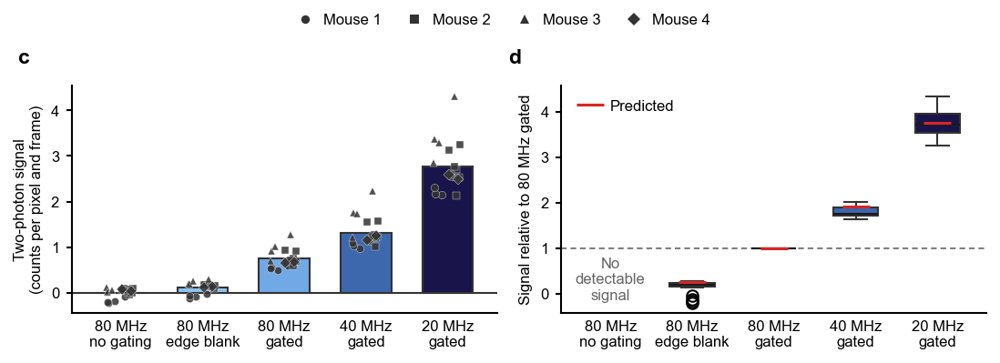

n = 18 positions from 4 sessions

              case0    case1    case2    case3    case4
signal        -0.00     0.12     0.75     1.32     2.76
gain          -0.02     0.14     1.00     1.79     3.77
predicted      0.13     0.25     1.00     1.91     3.75
snr            0.10     1.31     7.68    11.33    24.74
gain s.d.      0.18     0.16     0.00     0.11     0.34
gain med.      0.04     0.20     1.00     1.75     3.71


In [9]:
# ==========================================================
# Figure: two-photon signal (a) and gain (b). Settings first, plotting below.
# ==========================================================
F1_NAME = "fig1_signal"
F1_SIZE_MM = (WIDTH_2COL, 65)        # width, height in mm
F1_WIDTHS = (1, 1)                   # relative widths of panel a and panel b
F1_TICKLABELS = LABELS               # or ["C0", "C1", "C2", "C3", "C4"]

F1_YLABEL_A = "Two-photon signal\n(counts per pixel and frame)"
F1_YLABEL_B = "Signal relative to 80 MHz gated"
F1_YLIM_A = None                     # e.g. (0, 4.5). None = automatic, always including 0
F1_YLIM_B = None                     # e.g. (0, 5)

F1_POINTS_A = True                   # one dot per position on the bars
F1_POINTS_B = False                   # one dot per position on the boxes
F1_MARKERS = ["o", "s", "^", "D", "v", "P"]   # one marker per session
F1_SESSION_NAMES = {"2026-09-10": "Mouse 1", "2026-09-29": "Mouse 2", "2026-10-09": "Mouse 3", "2026-10-15": "Mouse 4"}    # legend text, e.g. {"2026-09-10": "Mouse 1", ...}
F1_SHOW_SESSION_LEGEND = True

F1_BAR_WIDTH = 0.62
F1_BOX_WIDTH = 0.55
F1_WHIS = 1.5                        # whiskers in IQR. (0, 100) = full range
F1_GAIN_CASES = DETECTED             # cases with a box. The others get F1_NO_SIGNAL_TEXT
F1_NO_SIGNAL_TEXT = "No\ndetectable\nsignal"
F1_UNITY_LINE = True                 # dashed line at 1 in panel b
F1_REFERENCE = "predicted"           # "predicted" (confocal duty cycle), "ideal" (f_ref / f) or None
F1_REFERENCE_LABEL = "Predicted"
F1_JITTER = 0.17                     # horizontal scatter of the dots, in case units

# ----------------------------------------------------------
rng = np.random.default_rng(0)
x = np.arange(N_CASE)
v_sig = sig2p[complete]
v_gain = gain2p[complete]
sess_of = np.array([s.split("/")[0] for s in np.array(SITES)[complete]])
sessions = list(dict.fromkeys(sess_of))
jit = rng.uniform(-F1_JITTER, F1_JITTER, v_sig.shape[0])


def dots(ax, j, values):
    for k, s in enumerate(sessions):
        m = sess_of == s
        ax.plot(j + jit[m], values[m], ls="", marker=F1_MARKERS[k % len(F1_MARKERS)],
                ms=PAPER_MARKERSIZE+1, mfc="0.2", markeredgecolor="1",
                markeredgewidth="0.2", alpha=0.85, zorder=4)


def y_from_zero(ax, lim):
    if lim is not None:
        ax.set_ylim(*lim)
    else:
        lo, hi = ax.get_ylim()
        ax.set_ylim(min(0, lo), hi)


with paper_style():
    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(F1_SIZE_MM[0] * MM, F1_SIZE_MM[1] * MM),
                                     layout="constrained", width_ratios=F1_WIDTHS)

    # a: mean signal, bars plus positions
    ax_a.bar(x, np.nanmean(v_sig, axis=0), width=F1_BAR_WIDTH, color=CASE_COLORS,
             edgecolor="0.2", zorder=2)
    if F1_POINTS_A:
        for j in range(N_CASE):
            dots(ax_a, j, v_sig[:, j])
    ax_a.axhline(0, color="0.2", lw=PAPER_LINEWIDTH, zorder=1)
    ax_a.set_ylabel(F1_YLABEL_A)
    y_from_zero(ax_a, F1_YLIM_A)

    # b: gain, boxes for the cases with a measurable signal
    bp = ax_b.boxplot([v_gain[:, j] for j in F1_GAIN_CASES], positions=F1_GAIN_CASES,
                      widths=F1_BOX_WIDTH, whis=F1_WHIS, patch_artist=True, showfliers=not F1_POINTS_B,
                      medianprops=dict(color="0.1", lw=PAPER_LINEWIDTH),
                      boxprops=dict(edgecolor="0.2", lw=PAPER_LINEWIDTH),
                      whiskerprops=dict(color="0.2", lw=PAPER_LINEWIDTH),
                      capprops=dict(color="0.2", lw=PAPER_LINEWIDTH), zorder=2)
    for patch, j in zip(bp["boxes"], F1_GAIN_CASES):
        patch.set_facecolor(CASE_COLORS[j])
    if F1_POINTS_B:
        for j in F1_GAIN_CASES:
            dots(ax_b, j, v_gain[:, j])
    for j in range(N_CASE):
        if j not in F1_GAIN_CASES:
            ax_b.text(j, -0.2, F1_NO_SIGNAL_TEXT, ha="center", va="bottom", color="0.4")
    if F1_UNITY_LINE:
        ax_b.axhline(1, color="0.5", lw=PAPER_LINEWIDTH, ls=(0, (3, 2)), zorder=1)
    if F1_REFERENCE is not None:
        ref = (np.nanmean(predicted[complete], axis=0) if F1_REFERENCE == "predicted"
               else F_REP[J_REF] / F_REP)
        cases = F1_GAIN_CASES if F1_REFERENCE == "predicted" else [j for j in F1_GAIN_CASES if j in GATED]
        ax_b.plot(cases, ref[cases], ls="", marker="_", ms=14, mew=1.5 * PAPER_LINEWIDTH,
                  color=C_REF, zorder=5, label=F1_REFERENCE_LABEL)
        ax_b.legend(loc="upper left", handletextpad=0.3)
    ax_b.set_ylabel(F1_YLABEL_B)
    y_from_zero(ax_b, F1_YLIM_B)

    for ax in (ax_a, ax_b):
        ax.set_xticks(x)
        ax.set_xticklabels(F1_TICKLABELS)
        ax.set_xlim(-0.6, N_CASE - 0.4)
        ax.tick_params(axis="x", length=0)
    panel_label(ax_a, "c", dy=10)
    panel_label(ax_b, "d", dy=10)

    if F1_SHOW_SESSION_LEGEND and (F1_POINTS_A or F1_POINTS_B) and len(sessions) > 1:
        handles = [plt.Line2D([], [], ls="", marker=F1_MARKERS[k % len(F1_MARKERS)],
                              ms=PAPER_MARKERSIZE + 1.5, mfc="0.2", mec="none",
                              label=F1_SESSION_NAMES.get(s, s)) for k, s in enumerate(sessions)]
        fig.legend(handles=handles, loc="outside upper center", ncol=len(handles),
                   handletextpad=0.2, columnspacing=1.2)

    save_paper(fig, F1_NAME)
    plt.show()

# numbers for the legend and the text
n_pos, n_sess = int(complete.sum()), len(sessions)
print(f"n = {n_pos} positions from {n_sess} sessions\n")
print(f"{'':<10}" + "".join(f"{c:>9}" for c in CASES))
for name, values in [("signal", sig2p), ("gain", gain2p), ("predicted", predicted), ("snr", snr)]:
    print(f"{name:<10}" + "".join(f"{v:9.2f}" for v in np.nanmean(values[complete], axis=0)))
print(f"{'gain s.d.':<10}" + "".join(f"{v:9.2f}" for v in np.nanstd(gain2p[complete], axis=0, ddof=1)))
print(f"{'gain med.':<10}" + "".join(f"{v:9.2f}" for v in np.nanmedian(gain2p[complete], axis=0)))

## Brighter and dimmer half, Supplementary Fig. 2

Check that the gain does not depend on where the signal is averaged. The split is made on the
two-photon image itself, not on the confocal, which shows different structures (nerve fibres
versus ganglion cells).

                    case0    case1    case2    case3    case4

relative gain to C2
whole field         -0.02     0.14     1.00     1.79     3.77
brighter half       -0.00     0.14     1.00     1.77     3.68
dimmer half         -0.06     0.12     1.00     1.82     3.92

signal level      (counts per pixel and frame)
whole field         -0.00     0.12     0.75     1.32     2.76
brighter half        0.01     0.15     0.93     1.63     3.37
dimmer half         -0.01     0.09     0.57     1.01     2.16


saved figS_bright_dim.pdf, figS_bright_dim.svg, figS_bright_dim.png


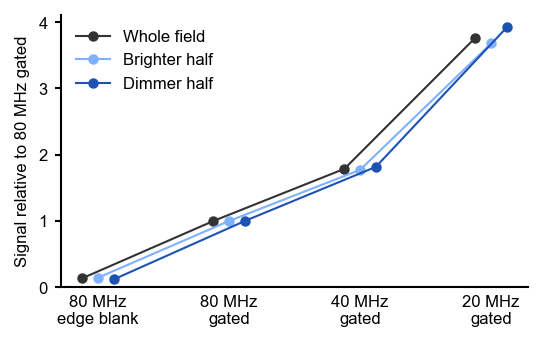

In [10]:
# ==========================================================
# Does the gain depend on where we average? Brighter and dimmer half of each position.
# ==========================================================
# The split is made on the two-photon image itself, pooled over the gated cases (C2 to C4) so that
# it does not favour any one of them, and then applied identically to all five cases. Every case is
# dark and offset corrected exactly like sig2p. If the gain is a property of the excitation, both
# halves give the same gain as the whole field. Settings first, plotting below.

BD_NAME = "figS_bright_dim"
BD_SIZE_MM = (WIDTH_1COL, 55)
BD_SPLIT_PCT = 50                     # percentile of the pooled image that separates the halves
BD_CASES = DETECTED                   # cases shown in the figure
BD_COLORS = {"whole field": "0.2", "brighter half": "#80b1ff", "dimmer half": "#1c53b2"}
BD_YLABEL = "Signal relative to 80 MHz gated"
BD_PANEL = None

# ----------------------------------------------------------
BD_REGIONS = ["whole field", "brighter half", "dimmer half"]
bd_sig = np.full((N_SITE, len(BD_REGIONS), N_CASE), np.nan)

for i, site in enumerate(SITES):
    if not complete[i]:
        continue
    ims = [read_image(site, find(site, j).stem).astype(np.float64) - ch2_dark[i, j] - offset[i, j]
           for j in range(N_CASE)]
    pooled = np.mean([ims[j] for j in GATED], axis=0)
    bright = pooled >= np.percentile(pooled, BD_SPLIT_PCT)
    for j in range(N_CASE):
        bd_sig[i, :, j] = ims[j].mean(), ims[j][bright].mean(), ims[j][~bright].mean()

bd_gain = bd_sig / bd_sig[:, :, [J_REF]]

print(f"{'':<16}" + "".join(f"{c:>9}" for c in CASES))
print(f"\n{'relative gain to C2':<16}")
for k, name in enumerate(BD_REGIONS):
    print(f"{name:<16}" + "".join(f"{v:9.2f}" for v in np.nanmean(bd_gain[complete][:, k], axis=0)))
print(f"\n{'signal level':<16}  (counts per pixel and frame)")
for k, name in enumerate(BD_REGIONS):
    print(f"{name:<16}" + "".join(f"{v:9.2f}" for v in np.nanmean(bd_sig[complete][:, k], axis=0)))

with paper_style():
    fig, ax = plt.subplots(figsize=(BD_SIZE_MM[0] * MM, BD_SIZE_MM[1] * MM), layout="constrained")
    x = np.arange(len(BD_CASES))
    for k, name in enumerate(BD_REGIONS):
        v = bd_gain[complete][:, k]
        ax.plot(x + (k - 1) * 0.12, [np.nanmean(v[:, j]) for j in BD_CASES], "o-", ms=PAPER_MARKERSIZE + 1,
                color=BD_COLORS[name], label=name.capitalize())
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[j] for j in BD_CASES])
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, None)
    ax.set_ylabel(BD_YLABEL)
    ax.legend(loc="upper left")
    if BD_PANEL:
        panel_label(ax, BD_PANEL)
    save_paper(fig, BD_NAME)
    plt.show()

## Figure 6: Bleaching within a recording & repeats

Per-frame signal over the 60 s, normalised to the first second and averaged over positions.
Flat means no bleaching. Only case2-4, case0/case1 have no signal to decay.

Some positions have the 20 MHz gated recording repeated at the end of the sequence, so the pair
brackets the whole exposure history of that position. A drop in 2p would be bleaching. CH1 is
reflectance and cannot bleach, so if the confocal moves as well, the sample drifted instead.
The repeat is evaluated exactly like the first recording: whole field, own dark, same offset.

position               gap (min)  between      2p  confocal
2026-09-29/5 case4          14.9        4   1.042     1.021
2026-09-29/6 case4          20.1        4   1.012     1.000
2026-09-29/7 case4          14.3        4   1.020     0.987
2026-10-09/1 case4          16.1        4   0.926     1.006
2026-10-09/3 case4          13.7        4   0.929     1.015
2026-10-09/4 case4          17.3        4   1.029     1.010
2026-10-09/5 case4          15.5        4   1.127     1.079
2026-10-15/1 case4          27.2        4   1.142     1.062
2026-10-15/2 case4          25.2        4   1.028     1.003

n = 9 positions from 3 sessions, 14 to 27 min after the first recording
two-photon  mean 1.028  s.d. 0.074  range 0.926 to 1.142
confocal    mean 1.020  s.d. 0.030  range 0.987 to 1.079


saved fig4_bleaching_and_repeats.pdf, fig4_bleaching_and_repeats.svg, fig4_bleaching_and_repeats.png


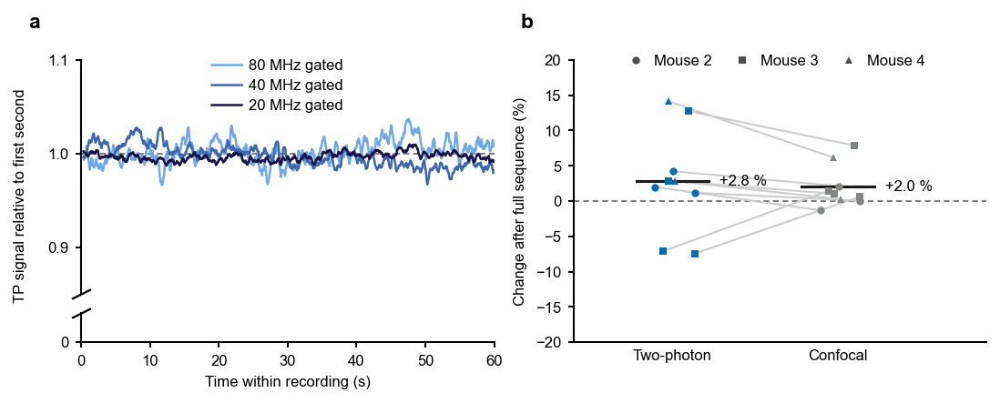

In [11]:
# ==========================================================
# Figure: bleaching within a recording. Settings first, plotting below.
# ==========================================================
B_SIZE_MM = (WIDTH_1COL, 55)          # width, height in mm
B_YLIM = (0.9, 1.1)                     # LSA: axes start at zero. (0.9, 1.1) to zoom in
B_YTICKS = np.arange(0.9, 1.2, 0.1)                      # e.g. np.arange(0, 1.21, 0.2). None = automatic
B_XLIM = (0, 60)
B_SMOOTH = 10                         # moving average, in frames
B_LINEWIDTH = 1.2 * PAPER_LINEWIDTH
B_XLABEL = "Time within recording (s)"
B_YLABEL = "TP signal relative to first second"
B_UNITY_LINE = True

# ==========================================================
# Repeats: the same configuration recorded again at the end of the sequence. Settings first.
# ==========================================================
# A drop in the two-photon signal could be bleaching or the sample moving. The confocal channel is
# reflectance and cannot bleach, so it tells the two apart: if it stays put, the sample did not move.
# The repeat is evaluated exactly like the first recording: whole field, its own dark, the
# same offset.
R_NAME = "fig4_bleaching_and_repeats"
R_SIZE_MM = (WIDTH_2COL, 70)          # width, height in mm. Same height as fig3_bleaching
R_AS_PERCENT = True                   # True: change in %, axis around 0. False: ratio, axis from 0
R_YLIM = None                         # e.g. (-20, 20) or (0, 1.2). None = automatic
R_GROUPS = ("Two-photon", "Confocal")
R_COLORS = (C_2P, C_CONF)   # the repeats are all 20 MHz gated
R_PAIR_LINES = True                   # connect the two channels of the same position
R_SHOW_MEAN = True                    # black bar and value at the mean
R_JITTER = 0.15
R_YLABEL = "Change after full sequence (%)" if R_AS_PERCENT else "Repeat relative to first recording"
R_MARKERS = globals().get("F1_MARKERS", ["o", "s", "^", "D", "v", "P"])
R_SESSION_NAMES = globals().get("F1_SESSION_NAMES", {s: s for s in SESSIONS})
R_SHOW_SESSION_LEGEND = True

## computations for repeats --------------------------------------------------------------
rep_label, rep_session, rep_2p, rep_conf, rep_gap, rep_between = [], [], [], [], [], []

for i, site in enumerate(SITES):
    for j in range(N_CASE):
        first, again = find(site, j), find(site, j, is_repeat=True)
        if first is None or again is None:
            continue
        dk, _ = dark_of(site, again.stem, j)
        sig_again = read_image(site, again.stem).mean() - dk - offset[i, j]
        conf_again = read_image(site, again.stem, "CH1").mean() - ch1_dark[i]
        rep_label.append(f"{site} {CASES[j]}")
        rep_session.append(site.split("/")[0])
        rep_2p.append(sig_again / sig2p[i, j])
        rep_conf.append(conf_again / confocal[i, j])
        rep_gap.append((again.t0 - first.t0) / 60)
        rep_between.append(sum(1 for r in INDEX if r.site == site and first.t0 < r.t0 < again.t0))

rep_session = np.array(rep_session)
rep_2p, rep_conf = np.array(rep_2p), np.array(rep_conf)
rep_gap, rep_between = np.array(rep_gap), np.array(rep_between)

print(f"{'position':<22}{'gap (min)':>10}{'between':>9}{'2p':>8}{'confocal':>10}")
for k, name in enumerate(rep_label):
    print(f"{name:<22}{rep_gap[k]:10.1f}{rep_between[k]:9d}{rep_2p[k]:8.3f}{rep_conf[k]:10.3f}")
print(f"\nn = {len(rep_2p)} positions from {len(set(rep_session))} sessions, "
      f"{rep_gap.min():.0f} to {rep_gap.max():.0f} min after the first recording")
for name, v in [("two-photon", rep_2p), ("confocal", rep_conf)]:
    print(f"{name:<11} mean {v.mean():.3f}  s.d. {v.std(ddof=1):.3f}  range {v.min():.3f} to {v.max():.3f}")

to_y = (lambda r: 100 * (r - 1)) if R_AS_PERCENT else (lambda r: r)
ys = [to_y(rep_2p), to_y(rep_conf)]
sessions = list(dict.fromkeys(rep_session))
jit = np.random.default_rng(1).uniform(-R_JITTER, R_JITTER, len(rep_2p))
# ----------------------------------------------------------


GRID = np.linspace(0, 60, 1500)


B_YLIM_LO    = (0, 0.03)     # stub: just enough to show the 0 tick
B_YLIM_HI    = (0.85, 1.05)  # where the traces actually live
B_BREAK_RAT  = (8, 1)        # height data panel : stub

with paper_style():
    fig = plt.figure(figsize=(R_SIZE_MM[0] * MM, R_SIZE_MM[1] * MM), layout="constrained")
    fig.get_layout_engine().set(hspace=0, h_pad=0.0001)        # otherwise the two halves drift apart
    gs = fig.add_gridspec(2, 2, width_ratios=(1, 1), height_ratios=B_BREAK_RAT)
    ax_hi = fig.add_subplot(gs[0, 0])
    ax_lo = fig.add_subplot(gs[1, 0], sharex=ax_hi)
    ax_b  = fig.add_subplot(gs[:, 1])

    # plot A --------------------------------
    for j in GATED:
        curves = []
        for i, site in enumerate(SITES):
            if not complete[i]:
                continue
            t = read_trace(site, find(site, j).stem) - ch2_dark[i, j] - offset[i, j]
            f = fps(site)
            curves.append(np.interp(GRID, np.arange(len(t)) / f, t / t[:int(f)].mean()))
        mean = np.convolve(np.mean(curves, axis=0), np.ones(B_SMOOTH) / B_SMOOTH, mode="valid")
        for ax in (ax_hi, ax_lo):                # same curve on both halves
            ax.plot(GRID[B_SMOOTH - 1:], mean, lw=B_LINEWIDTH, color=CASE_COLORS[j],
                    label=LABELS[j].replace("\n", " "))

    if B_UNITY_LINE:
        ax_hi.axhline(1, color="0.5", lw=PAPER_LINEWIDTH, ls=(0, (3, 2)), zorder=1)

    ax_hi.set(xlim=B_XLIM, ylim=B_YLIM_HI)
    ax_lo.set(xlim=B_XLIM, ylim=B_YLIM_LO, xlabel=B_XLABEL, yticks=[0])
    if B_YTICKS is not None:
        ax_hi.set_yticks(B_YTICKS)

    ax_hi.tick_params(labelbottom=False, bottom=False)
    ax_hi.spines["bottom"].set_visible(False)
    ax_lo.spines["top"].set_visible(False)
    ax_hi.set_ylabel(B_YLABEL)
    ax_hi.yaxis.set_label_coords(-0.13, 0.42)    # nudge so it reads for both halves

    # break marks: bottom corners of the top axes, top corners of the stub
    kw = dict(marker=[(-1, -0.5), (1, 0.5)], markersize=10, linestyle="none",
              color="k", mec="k", mew=1.1, clip_on=False)
    ax_hi.plot([0], [0], transform=ax_hi.transAxes, **kw)
    ax_lo.plot([0], [1], transform=ax_lo.transAxes, **kw)

    ax_hi.legend(loc=(0.3, 0.75), handletextpad=0.5, labelspacing=0.4)

    # plot B ---------------------------------
    if R_PAIR_LINES:
        for k in range(len(rep_2p)):
            ax_b.plot([0 + jit[k], 1 + jit[k]], [ys[0][k], ys[1][k]], color="0.8",
                    lw=PAPER_LINEWIDTH, zorder=1)
        for g, (y, color) in enumerate(zip(ys, R_COLORS)):
            for s_i, s in enumerate(sessions):
                m = rep_session == s
                ax_b.plot(g + jit[m], y[m], ls="", marker=R_MARKERS[s_i % len(R_MARKERS)],
                        ms=PAPER_MARKERSIZE + 1, mfc=color, mec="none", zorder=3)
            if R_SHOW_MEAN:
                ax_b.plot([g - 0.22, g + 0.22], [y.mean()] * 2, color="0.1", lw=1.5 * PAPER_LINEWIDTH, zorder=2)
                ax_b.annotate(f"{y.mean():+.1f} %" if R_AS_PERCENT else f"{y.mean():.2f}",
                            (g + 0.24, y.mean()), xytext=(4, 0), textcoords="offset points",
                            ha="left", va="center")
    
        ax_b.axhline(0 if R_AS_PERCENT else 1, color="0.5", lw=PAPER_LINEWIDTH, ls=(0, (3, 2)), zorder=0)
        if R_YLIM is not None:
            ax_b.set_ylim(*R_YLIM)
        elif R_AS_PERCENT:
            lim = 5 * np.ceil(1.3 * max(np.abs(np.concatenate(ys))) / 5)
            ax_b.set_ylim(-lim, lim)
        else:
            ax_b.set_ylim(0, 1.2)
        ax_b.set_xticks([0, 1])
        ax_b.set_xticklabels(R_GROUPS)
        ax_b.set_xlim(-0.6, 1.9)
        ax_b.tick_params(axis="x", length=0)
        ax_b.set_ylabel(R_YLABEL)
        if R_SHOW_SESSION_LEGEND and len(sessions) > 1:
            handles = [plt.Line2D([], [], ls="", marker=R_MARKERS[k % len(R_MARKERS)],
                                ms=PAPER_MARKERSIZE + 1, mfc="0.3", mec="none",
                                label=R_SESSION_NAMES.get(s, s)) for k, s in enumerate(sessions)]
            ax_b.legend(handles=handles, loc=(0.1, 0.95), ncol=len(handles),
                    handletextpad=0.2, columnspacing=1.0)


    panel_label(ax_hi, "a", dy=15)
    panel_label(ax_b, "b", dy=15)


    save_paper(fig, R_NAME)
    plt.show()

## Images

Rows = position, columns = case. Same intensity scale within a row, so the brightness difference
across a row is the real effect. Scale bar 20 um.

In [12]:
import seaborn as sns

def scalebar(ax, site, shape, um=20):
    h, w = shape
    n = um / px_um(site)
    ax.add_patch(Rectangle((w - n - 0.05 * w, h - 0.09 * h), n, 0.012 * h, color="w", lw=0))


def montage(sites, ch="CH2", log=False, name=None, detailed=False, subplot_label=None):
    cmap = "mako" if ch == "CH2" else "gray"
    with paper_style():
        fig, axes = plt.subplots(len(sites), N_CASE, figsize=(WIDTH_2COL * MM, len(sites) * 37 * MM), layout="constrained", squeeze=False)
                                #figsize=((1.5 * N_CASE, 1.7 * len(sites))), squeeze=False)
        for row, site in enumerate(sites):
            i = SITES.index(site)
            imgs = [None if find(site, j) is None
                    else read_image(site, find(site, j).stem, ch)
                        - (ch2_dark[i, j] if ch == "CH2" else ch1_dark[i])
                    for j in range(N_CASE)]
            vmax = np.percentile(np.concatenate([im.ravel() for im in imgs if im is not None]), 99.7)
            lo = np.nanmean(ch2_noise[i]) if ch == "CH2" else vmax / 100

            for j in range(N_CASE):
                ax = axes[row][j]
                ax.set_xticks([]), ax.set_yticks([])
                for sp in ax.spines.values():
                    sp.set_visible(False)
                if j == 0:
                    if detailed:
                        #ax.set_ylabel(site, fontsize=9)
                        ax.set_ylabel(site.replace("2026-09-10/left-eye/", "mouse 1, pos ")
                                                .replace("2026-09-29/", "mouse 2, pos ")
                                                .replace("2026-10-09/", "mouse 3, pos ")
                                                .replace("2026-10-15/", "mouse 4, pos "))
                if imgs[j] is None:
                    continue
                if log:
                    ax.imshow(np.clip(imgs[j], lo, None), cmap=cmap, norm=LogNorm(lo, vmax))
                else:
                    ax.imshow(imgs[j], cmap=cmap, vmin=lo, vmax=vmax)
                scalebar(ax, site, imgs[j].shape)
                if row == 0:
                    ax.set_title(LABELS[j].replace("\n", " "), fontsize=8)
        #if detailed:
        #    fig.suptitle(f"{'2p' if ch == 'CH2' else 'confocal'}, {'log' if log else 'linear'} scale", y=1.0, fontsize=10)
        if subplot_label:
            panel_label(axes[0][0], subplot_label)
        fig.tight_layout(pad=0.2, w_pad=1.0, h_pad=0.4)
        if name:
            save_paper(fig, name)
        display(fig)
        plt.close(fig)


#for session in SESSIONS:
#    montage([s for s in SITES if s.startswith(session)], ch="CH2",
#            name=f"fig5_2p_{session}_linear", detailed=True)

### Figure 5 a,b: representative example of images

saved representative_2p_linear.pdf, representative_2p_linear.svg, representative_2p_linear.png


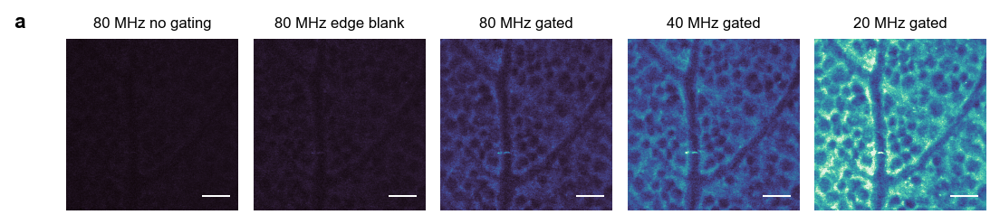

saved representative_confocal_linear.pdf, representative_confocal_linear.svg, representative_confocal_linear.png


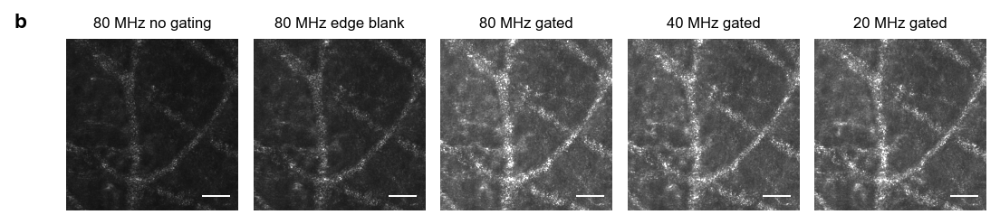

In [13]:
montage(["2026-10-09/5"], ch="CH2", name=f"representative_2p_linear", subplot_label="a")
montage(["2026-10-09/5"], ch="CH1", name=f"representative_confocal_linear", subplot_label="b")

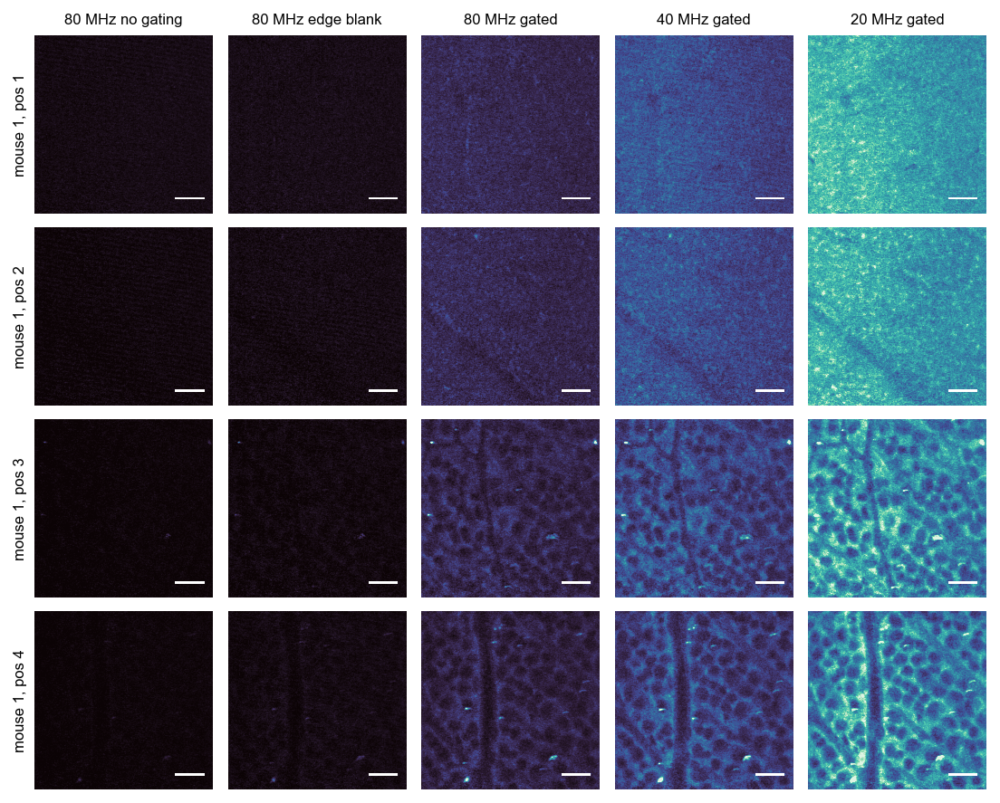

In [14]:
for i, session in enumerate(SESSIONS):
    if i < 1:
        montage([s for s in SITES if s.startswith(session)], ch="CH2", detailed=True, name=None)

saved supplementary_fig4_2p_linear_2026-09-10.pdf, supplementary_fig4_2p_linear_2026-09-10.svg, supplementary_fig4_2p_linear_2026-09-10.png


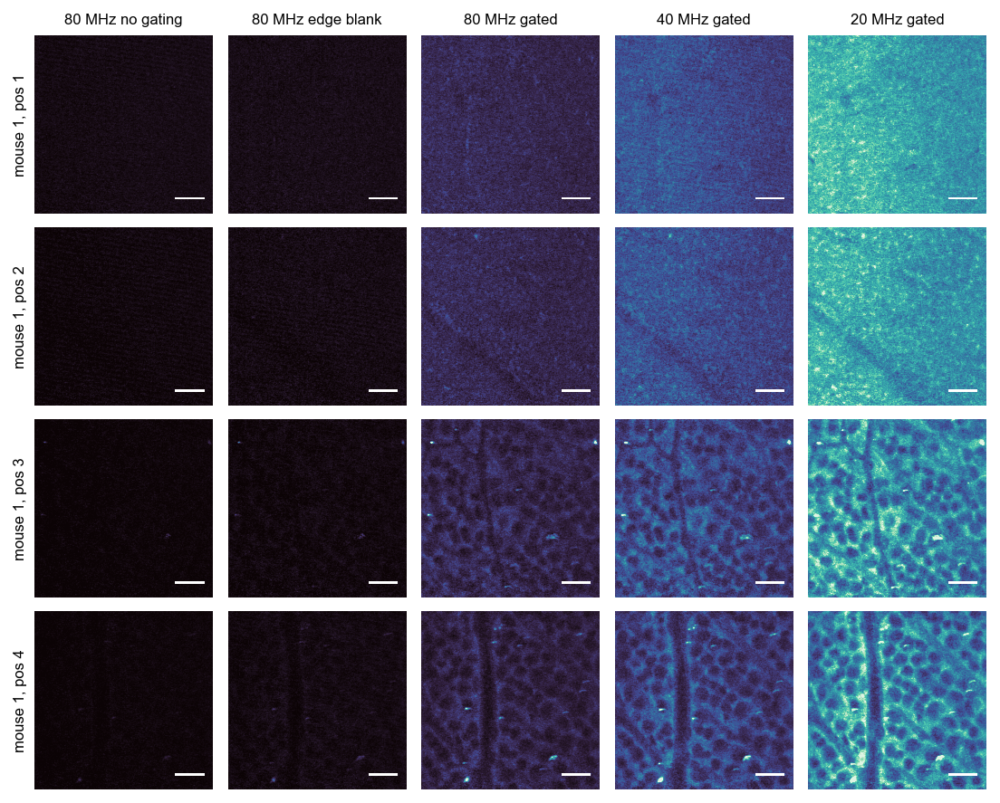

saved supplementary_fig4_2p_linear_2026-09-29.pdf, supplementary_fig4_2p_linear_2026-09-29.svg, supplementary_fig4_2p_linear_2026-09-29.png


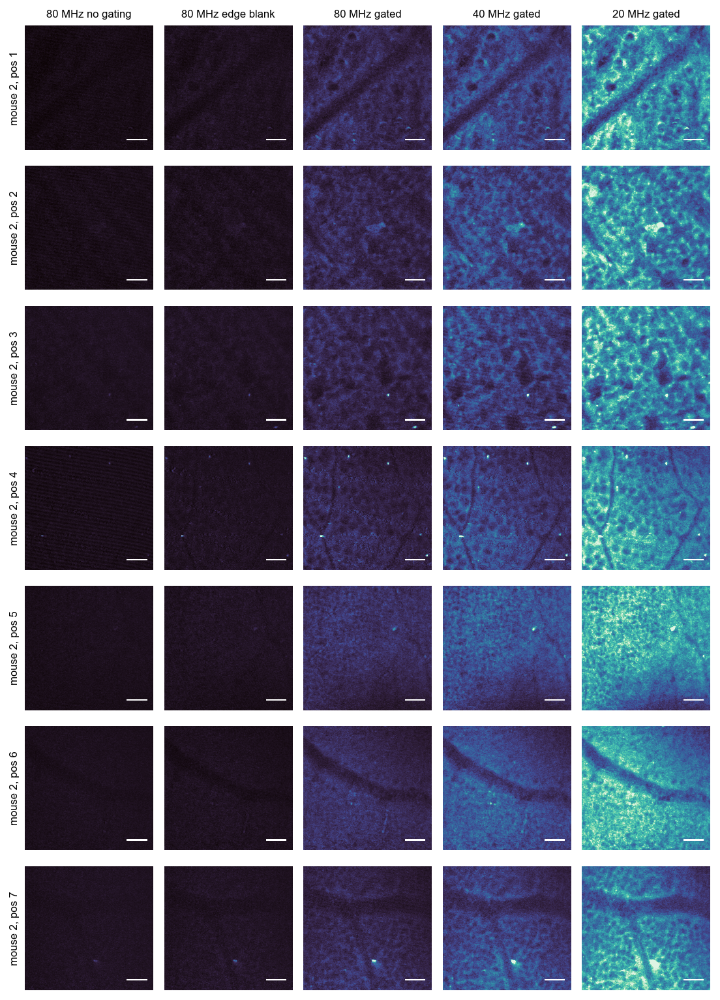

saved supplementary_fig4_2p_linear_2026-10-09.pdf, supplementary_fig4_2p_linear_2026-10-09.svg, supplementary_fig4_2p_linear_2026-10-09.png


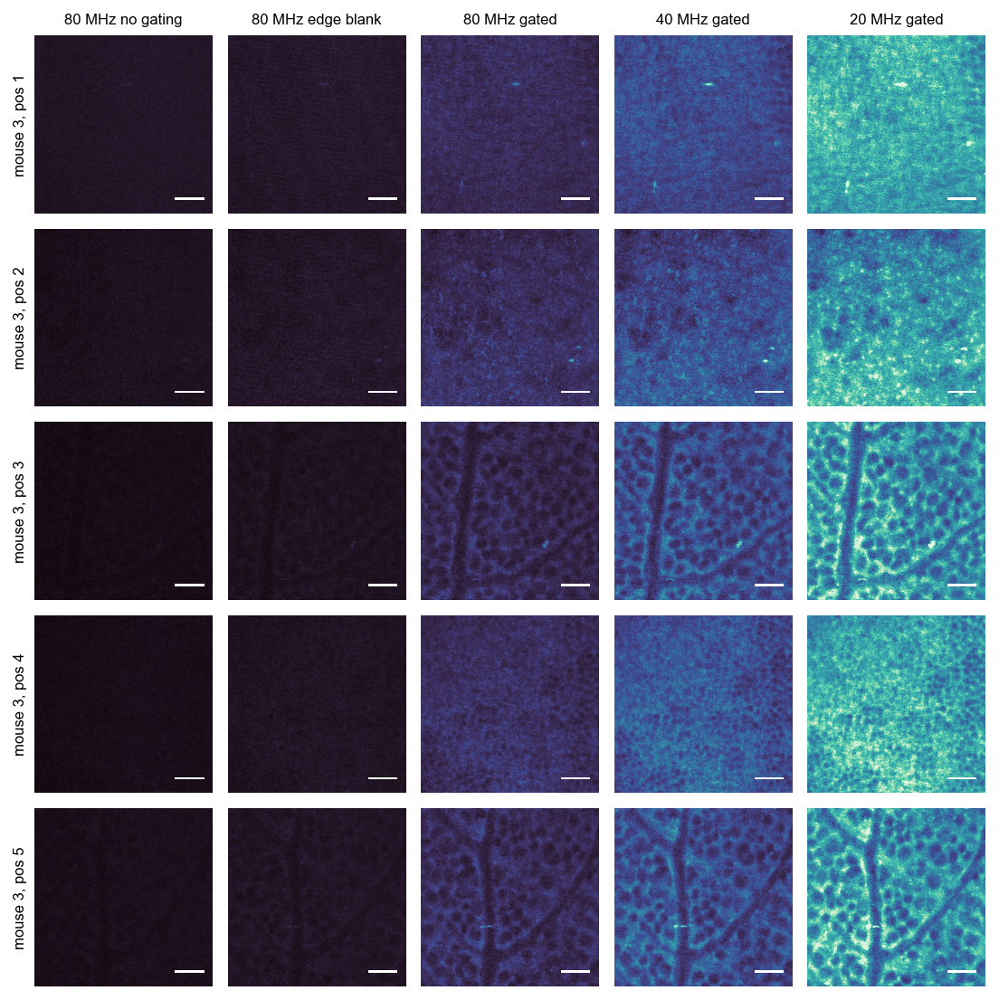

saved supplementary_fig4_2p_linear_2026-10-15.pdf, supplementary_fig4_2p_linear_2026-10-15.svg, supplementary_fig4_2p_linear_2026-10-15.png


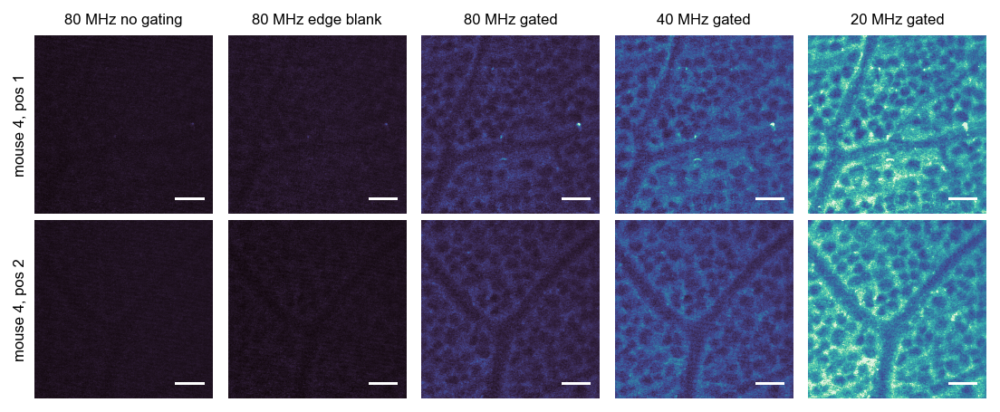

In [15]:
for session in SESSIONS:
    montage([s for s in SITES if s.startswith(session)], ch="CH2", detailed=True,
            name=f"supplementary_fig4_2p_linear_{session}")

Same images, log scale, floor at one noise unit of the 60 s average. Brings up the dim structure
in case0/case1 that the linear scale hides. Costs contrast at the bright end, where the structure
is a small modulation on a large mean.

saved fig6_2p_2026-09-10_log.pdf, fig6_2p_2026-09-10_log.svg, fig6_2p_2026-09-10_log.png


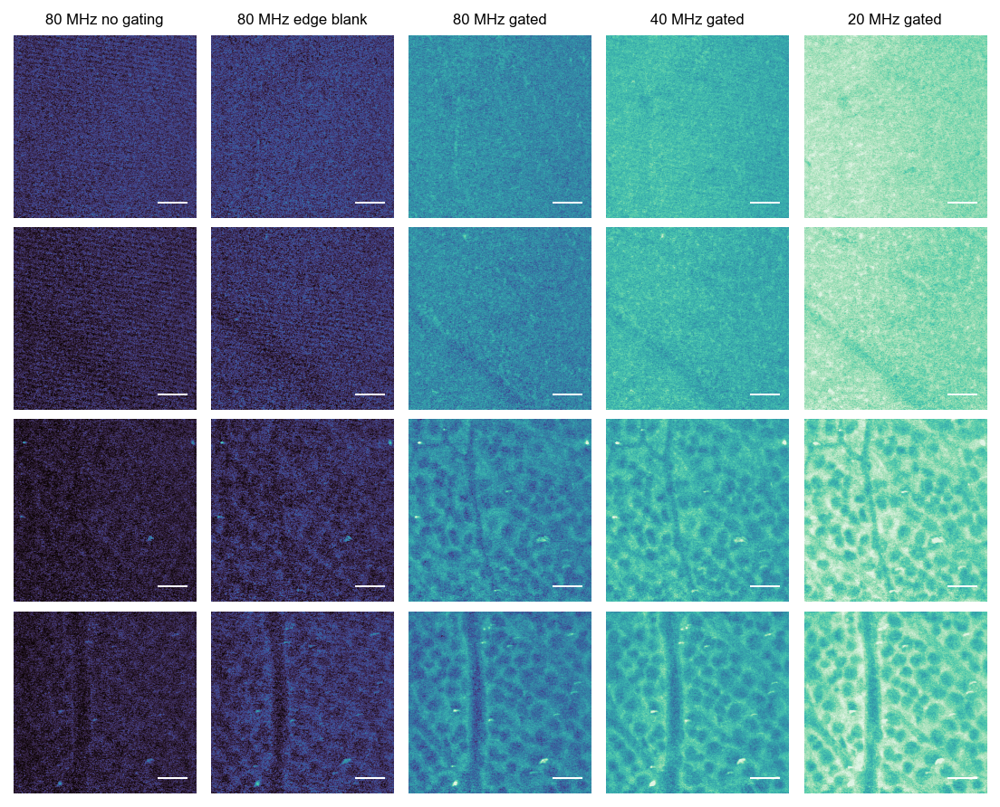

saved fig6_2p_2026-09-29_log.pdf, fig6_2p_2026-09-29_log.svg, fig6_2p_2026-09-29_log.png


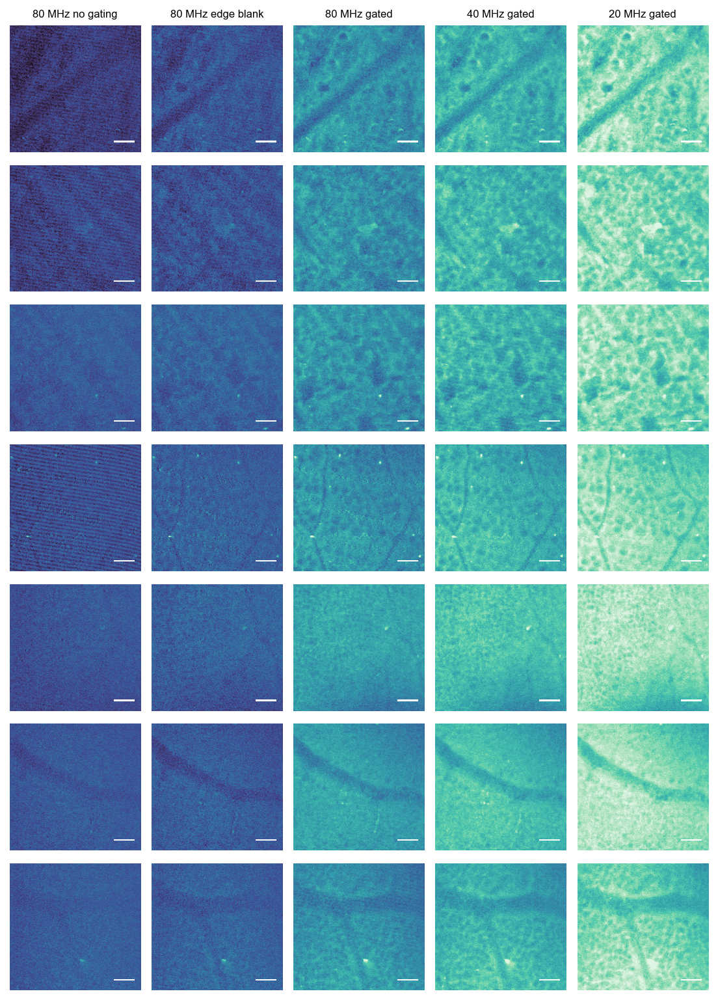

saved fig6_2p_2026-10-09_log.pdf, fig6_2p_2026-10-09_log.svg, fig6_2p_2026-10-09_log.png


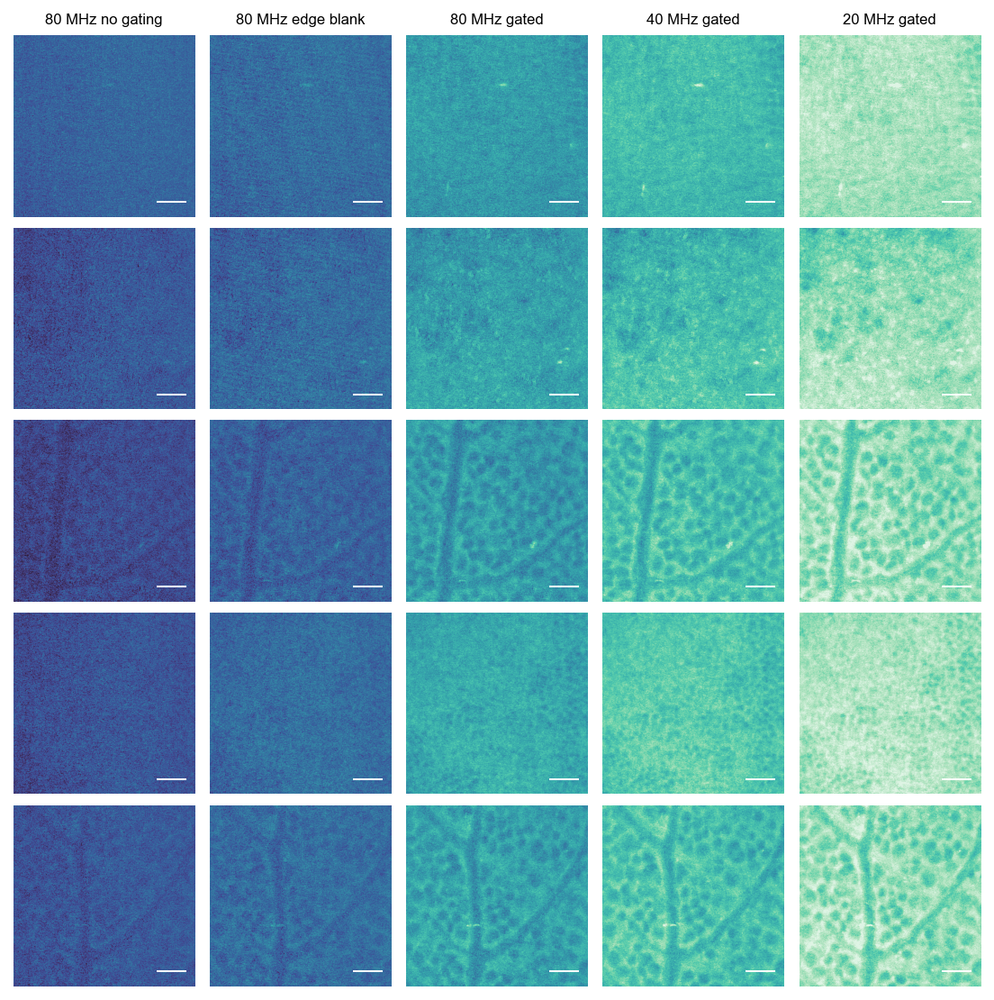

saved fig6_2p_2026-10-15_log.pdf, fig6_2p_2026-10-15_log.svg, fig6_2p_2026-10-15_log.png


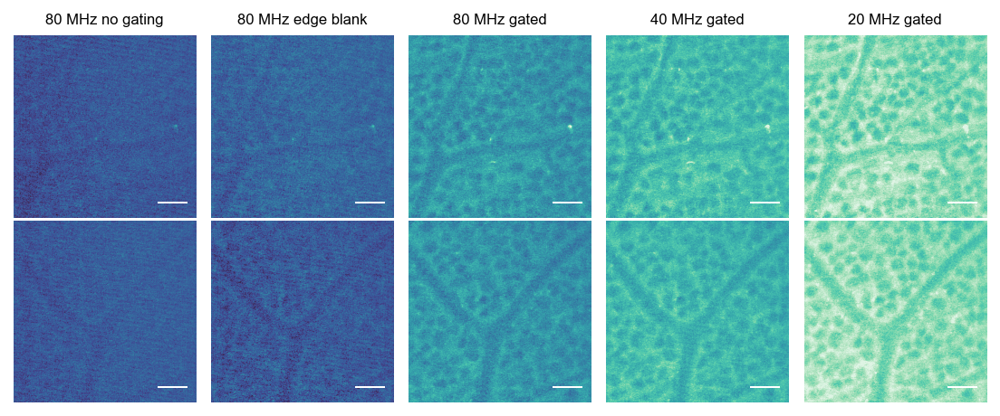

In [16]:
for session in SESSIONS:
    montage([s for s in SITES if s.startswith(session)], ch="CH2", log=True,
            name=f"fig6_2p_{session}_log")

## Confocal images

Same layout, CH1 instead of CH2, shared scale within a row. Confocal is linear in power, so the
brightness step from case0 to case2 across a row *is* the duty factor, the same number that goes
into `confocal_ratio`. case2/3/4 look the same because pulse picking does not change the average
power, only the pulse energy.

saved supplementary_fig5_confocal_2026-09-10.pdf, supplementary_fig5_confocal_2026-09-10.svg, supplementary_fig5_confocal_2026-09-10.png


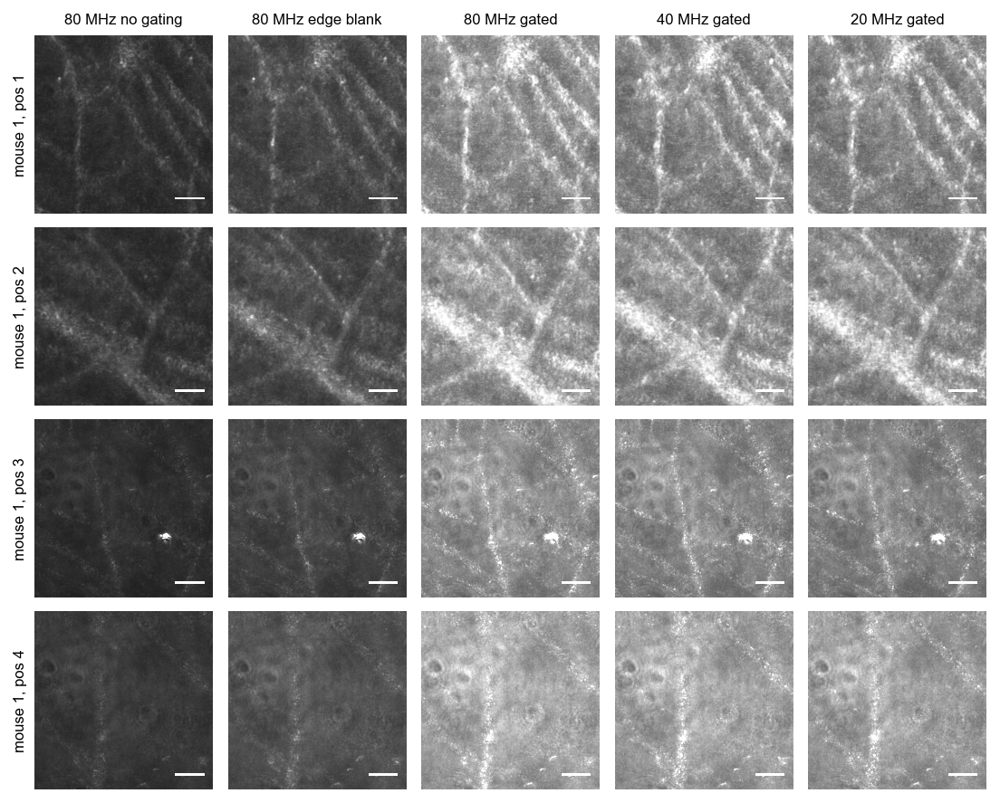

saved supplementary_fig5_confocal_2026-09-29.pdf, supplementary_fig5_confocal_2026-09-29.svg, supplementary_fig5_confocal_2026-09-29.png


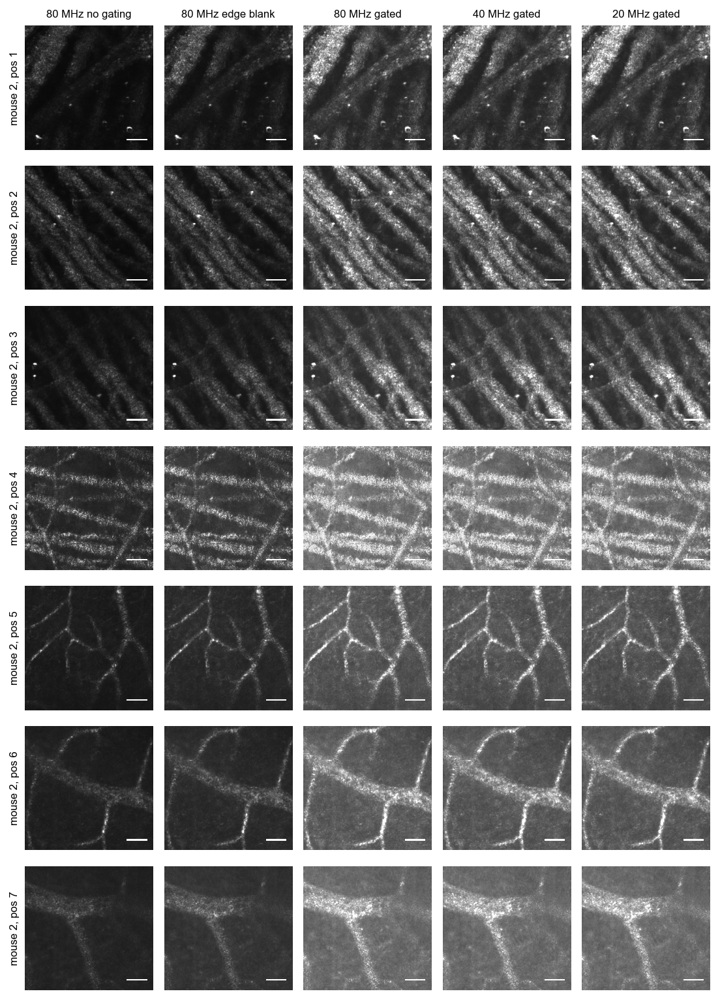

saved supplementary_fig5_confocal_2026-10-09.pdf, supplementary_fig5_confocal_2026-10-09.svg, supplementary_fig5_confocal_2026-10-09.png


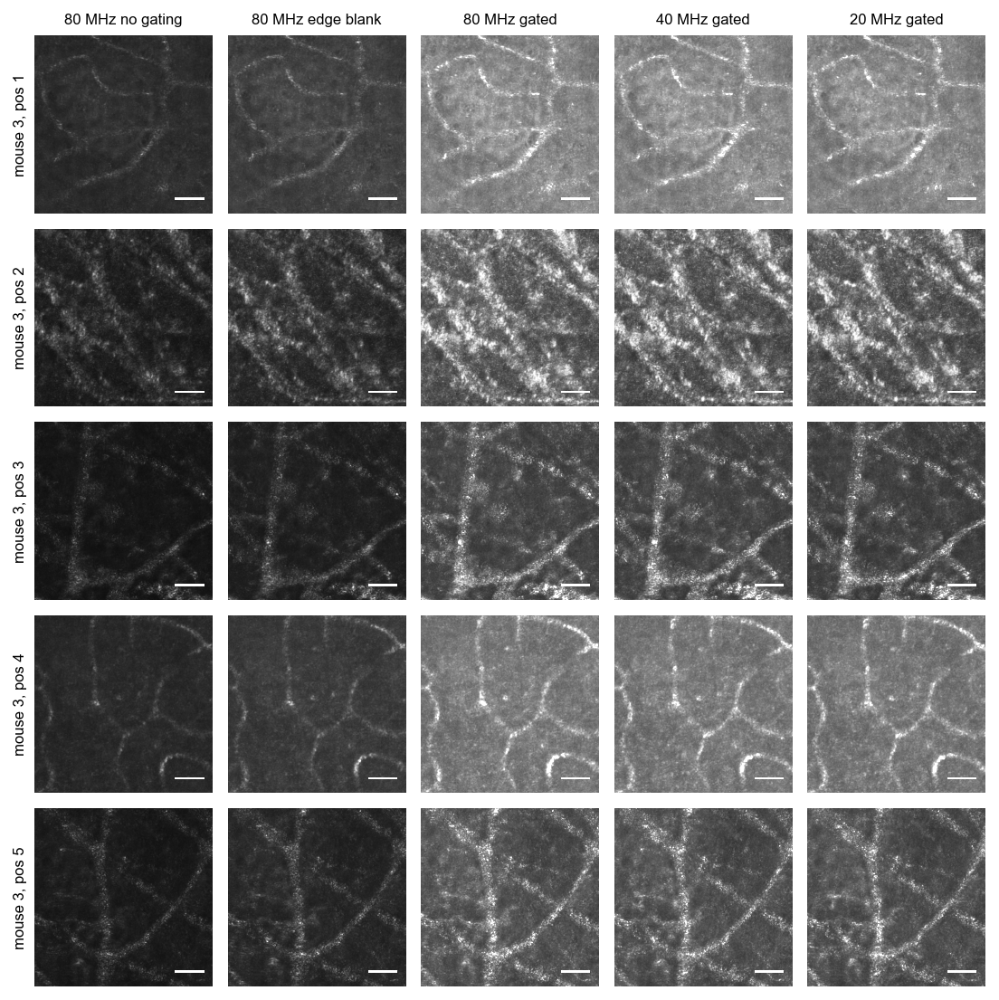

saved supplementary_fig5_confocal_2026-10-15.pdf, supplementary_fig5_confocal_2026-10-15.svg, supplementary_fig5_confocal_2026-10-15.png


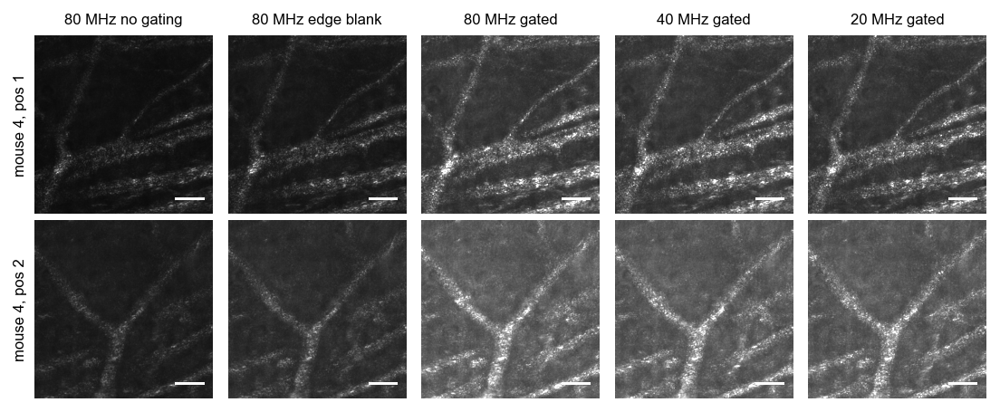

In [17]:
for session in SESSIONS:
    montage([s for s in SITES if s.startswith(session)], ch="CH1", detailed=True,
            name=f"supplementary_fig5_confocal_{session}")

## Supplementary Table 1: Table export (.csv)

Every recording

In [18]:
with open(DERIVED / "summary.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["session", "site", "case", "is_repeat", "stem", "t0", "rep_MHz",
                "signal", "noise", "snr", "confocal", "clip_pct"])
    for r in INDEX:
        i = SITES.index(r.site)
        dk, nz = dark_of(r.site, r.stem, r.case)
        sig = read_image(r.site, r.stem).mean() - dk - offset[i, r.case]
        conf = read_image(r.site, r.stem, "CH1").mean() - ch1_dark[i]
        w.writerow([r.session, r.site, CASES[r.case], r.is_repeat, r.stem, r.t0,
                    int(F_REP[r.case]), round(sig, 3), round(nz, 3),
                    round(sig / nz, 3), round(conf, 3),
                    round(100 * read_clip(r.site, r.stem), 3)])

print(f"wrote {DERIVED / 'summary.csv'}")

wrote data\derived\summary.csv


## Supplementary Fig. 1: Composition of the PMT reading

What the detector reads over the whole field, split into the blanked backward-scan dark, the
forward/backward offset measured with PMT2 off, and the two-photon signal that all gains are
computed from. By default only positions with a PMT-off control are used, so the offset is
measured, not assumed.

saved figS_pmt_composition.pdf, figS_pmt_composition.svg, figS_pmt_composition.png


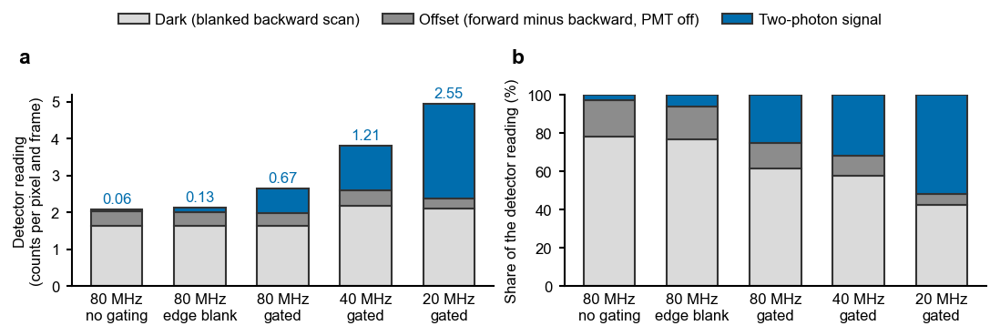

n = 2 positions: 2026-10-15/1, 2026-10-15/2

                case0    case1    case2    case3    case4
dark            1.628    1.628    1.628    2.185    2.102
offset          0.395    0.367    0.346    0.405    0.282
signal          0.057    0.130    0.667    1.205    2.548
raw             2.080    2.125    2.641    3.794    4.932
signal (%)        2.7      6.1     25.3     31.8     51.7


In [19]:
# ==========================================================
# Figure: what the PMT reads, split into dark, offset and two-photon signal
# ==========================================================
# Over the whole field, the forward-scan reading is exactly
#     raw = dark + offset + signal
#   dark    ch2_dark: blanked backward scan of the same recording (case0/case1 borrow the darkest
#           gated one at that position)
#   offset  offset: forward scan without light minus that dark, per configuration. Measured where a
#           control exists, the mean over the controls everywhere else
#   signal  sig2p: what is left, and what every gain is computed from

C_NAME = "figS_pmt_composition"
C_SITES = "measured"                 # "measured" = positions with a PMT-off control, "all", or a list
C_SIZE_MM = (WIDTH_2COL, 60)         # width, height in mm
C_FRACTION_PANEL = True              # panel b: each part as a percentage of the raw reading
C_TICKLABELS = LABELS
C_BAR_WIDTH = 0.62
C_COLORS = {"dark": "#DADADA", "offset": "#8C8C8C", "signal": C_2P}
C_LABELS = {"dark": "Dark (blanked backward scan)",
            "offset": "Offset (forward minus backward, PMT off)",
            "signal": "Two-photon signal"}
C_YLABEL_A = "Detector reading\n(counts per pixel and frame)"
C_YLABEL_B = "Share of the detector reading (%)"
C_SIGNAL_VALUES = True               # print the mean signal above each bar in panel a

# ----------------------------------------------------------
if isinstance(C_SITES, str):
    sel = has_control.copy() if C_SITES == "measured" else complete.copy()
else:
    sel = np.array([s in C_SITES for s in SITES])
sel &= complete
if not sel.any():
    raise ValueError("no positions selected. Use C_SITES = 'all' or pick positions with a control")

parts = {"dark": ch2_dark[sel], "offset": offset[sel], "signal": sig2p[sel]}
mean = {k: np.nanmean(v, axis=0) for k, v in parts.items()}
raw = sum(mean.values())
x = np.arange(N_CASE)

with paper_style():
    ncol = 2 if C_FRACTION_PANEL else 1
    fig, axes = plt.subplots(1, ncol, figsize=(C_SIZE_MM[0] * MM, C_SIZE_MM[1] * MM),
                             layout="constrained", squeeze=False)
    axes = axes[0]

    panels = [(axes[0], mean, C_YLABEL_A)]
    if C_FRACTION_PANEL:
        panels.append((axes[1], {k: 100 * v / raw for k, v in mean.items()}, C_YLABEL_B))

    for ax, values, ylabel in panels:
        bottom = np.zeros(N_CASE)
        for k in ("dark", "offset", "signal"):
            ax.bar(x, values[k], C_BAR_WIDTH, bottom=bottom, color=C_COLORS[k],
                   edgecolor="0.2", label=C_LABELS[k], zorder=2)
            bottom = bottom + values[k]
        ax.set_xticks(x)
        ax.set_xticklabels(C_TICKLABELS)
        ax.tick_params(axis="x", length=0)
        ax.set_ylabel(ylabel)
        ax.set_ylim(0, None)

    if C_SIGNAL_VALUES:
        for j in range(N_CASE):
            axes[0].annotate(f"{mean['signal'][j]:.2f}", (j, raw[j]), xytext=(0, 2),
                             textcoords="offset points", ha="center", va="bottom", color=C_2P)
    if C_FRACTION_PANEL:
        axes[1].set_ylim(0, 100)
    for ax, letter in zip(axes, "ab"):
        panel_label(ax, letter, dx=-28, dy=15)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=3, handletextpad=0.4,
               columnspacing=1.5)
    save_paper(fig, C_NAME)
    plt.show()

print(f"n = {sel.sum()} positions: {', '.join(np.array(SITES)[sel])}\n")
print(f"{'':<12}" + "".join(f"{c:>9}" for c in CASES))
for k in ("dark", "offset", "signal"):
    print(f"{k:<12}" + "".join(f"{v:9.3f}" for v in mean[k]))
print(f"{'raw':<12}" + "".join(f"{v:9.3f}" for v in raw))
print(f"{'signal (%)':<12}" + "".join(f"{v:9.1f}" for v in 100 * mean['signal'] / raw))

## Helper script: Manuscript numbers

Every number the manuscript quotes, computed from the variables above and grouped by where it
appears in the text. Also written to `derived/manuscript_numbers.json`.

In [20]:
# Values are mean ± s.d. over positions unless the line says otherwise.
import json
from scipy.signal import find_peaks
from scipy.ndimage import binary_erosion

POWER_MW = 2.0                        # average power after the objective, all configurations
N_BOOT = 20000                        # bootstrap resamples for confidence intervals
OSC_RUNS = {"40 MHz": "2026-10-12_40mhz", "20 MHz": "2026-10-12_20mhz"}   # photodiode records

NUM = {}


def ms(a):
    a = np.asarray(a, dtype=float)
    return float(np.nanmean(a)), float(np.nanstd(a, ddof=1))


def line(key, label, value, fmt="{:.2f}"):
    """Print one number and keep it for the json. A tuple is (mean, s.d.), a list is one per case."""
    if isinstance(value, tuple):
        txt = fmt.format(value[0]) + " ± " + fmt.replace("+", "").format(value[1])
    elif isinstance(value, (list, np.ndarray)):
        value = [float(v) for v in value]
        txt = "  ".join(fmt.format(v) for v in value)
    elif isinstance(value, str):
        txt = value
    else:
        value = float(value)
        txt = fmt.format(value)
    NUM[key] = value
    print(f"  {label:<62} {txt}")


def head(title):
    print(f"\n{title}\n" + "-" * len(title))


def boot_ci(stat, n, seed=0):
    """95 % percentile interval of stat(index) over positions resampled with replacement."""
    rng = np.random.default_rng(seed)
    vals = [stat(rng.integers(0, n, n)) for _ in range(N_BOOT)]
    return [float(v) for v in np.percentile(vals, [2.5, 97.5])]


c = complete
pos = np.array(SITES)[c]
mouse = np.array([s.split("/")[0] for s in pos])
mice = list(dict.fromkeys(mouse))
sig, gain, pred, cr = sig2p[c], gain2p[c], predicted[c], confocal_ratio[c]
print("columns of the per-case lines:", "  ".join(CASES))

# ----------------------------------------------------------
head("Dataset (Methods, all legends)")
line("n_positions", "positions with all five configurations", len(pos), "{:.0f}")
line("n_mice", "mice", len(mice), "{:.0f}")
line("positions_per_mouse", "positions per mouse  (" + ", ".join(mice) + ")",
     [int((mouse == m).sum()) for m in mice], "{:.0f}")
print("  excluded:", ", ".join(SKIP))

# ----------------------------------------------------------
head("Duty cycle from the confocal channel (Results, Table 1)")
line("conf_C1_over_C0", "confocal C1 / C0, edge blanking", ms(cr[:, 1] / cr[:, 0]))
line("conf_C2_over_C1", "confocal C2 / C1, backward scan blanking", ms(1 / cr[:, 1]))
line("conf_C2_over_C0", "confocal C2 / C0, both", ms(1 / cr[:, 0]))
D = cr[:, [0]] / cr                                    # on-time fraction, C0 = 1
line("D", "on-time fraction D", np.nanmean(D, axis=0), "{:.3f}")
line("D_C2", "on-time fraction D of C2", ms(D[:, 2]), "{:.3f}")
line("conf_C3_rel_C2", "confocal C3 / C2, pulse picking leaves power constant", ms(cr[:, 3]))
line("conf_C4_rel_C2", "confocal C4 / C2", ms(cr[:, 4]))

# ----------------------------------------------------------
head("Table 1")
energy = POWER_MW * 1e-3 / (np.nanmean(D, axis=0) * F_REP * 1e6) * 1e12
line("pulse_energy_pJ", f"pulse energy at {POWER_MW:g} mW (pJ)", energy, "{:.0f}")
line("gain_pred_mean", "gain vs C2, predicted", np.nanmean(pred, axis=0))
line("gain_meas_mean", "gain vs C2, measured, mean", np.nanmean(gain, axis=0))
line("gain_meas_sd", "gain vs C2, measured, s.d.", np.nanstd(gain, axis=0, ddof=1))
power_eq = np.sqrt(np.nanmean(pred[:, 0]) / np.nanmean(pred, axis=0))
line("power_equal_signal_pred", "average power for the signal of C0 (C0 = 1), predicted", power_eq)

# ----------------------------------------------------------
head("Pulse picking gain (Results, Fig. 5)")
for j in (3, 4):
    line(f"gain_C{j}", f"C{j} / C2, measured", ms(gain[:, j]))
    line(f"pred_C{j}", f"C{j} / C2, predicted", ms(pred[:, j]))
    line(f"meas_over_pred_C{j}", f"C{j}, measured / predicted, per position", ms(gain[:, j] / pred[:, j]))
    per_mouse = [np.nanmean(gain[mouse == m, j]) for m in mice]
    line(f"gain_C{j}_per_mouse", f"C{j} / C2, mean per mouse", per_mouse)
    line(f"gain_C{j}_over_mice", f"C{j} / C2, mean ± s.d. over the {len(mice)} mice", ms(per_mouse))
line("C4_over_C3", "C4 / C3 per position (ideal 2)", ms(gain[:, 4] / gain[:, 3]))

# ----------------------------------------------------------
head("Gating gain, ungated signal close to the noise floor (Results)")
for j in (0, 1):
    line(f"gain_C{j}", f"C{j} / C2, measured", ms(gain[:, j]))
    line(f"pred_C{j}", f"C{j} / C2, predicted", ms(pred[:, j]))
line("C0_below_noise", "positions with C0 below the noise floor (SNR < 1)", int((snr[c][:, 0] < 1).sum()), "{:.0f}")
line("C0_negative", "positions with negative C0 after correction", int((sig[:, 0] < 0).sum()), "{:.0f}")
line("C0_per_mouse", "C0 signal, mean per mouse (counts)", [np.nanmean(sig[mouse == m, 0]) for m in mice], "{:.3f}")

# ----------------------------------------------------------
head("Gating gain and combined gain (abstract, Results)")
# The ungated signal is below the detection limit, so C4 / C0 cannot be measured directly.
# Gating gain = (power during the recorded window, C2 relative to C0)^2, from the confocal channel.
# Combined gain = measured pulse picking gain x predicted gating gain, per position.
gate_pred = (1 / cr[:, 0]) ** 2
line("gating_gain_pred", "gating gain C2 / C0, predicted from the confocal duty cycle", ms(gate_pred), "{:.1f}")
line("combined_gain", "C4 / C0, measured picking gain x predicted gating gain", ms(gain[:, 4] * gate_pred), "{:.1f}")
line("combined_gain_pred", "C4 / C0, all predicted", ms(pred[:, 4] / pred[:, 0]), "{:.1f}")
line("signal_mean", "two-photon signal, mean over positions (counts per pixel and frame)", np.nanmean(sig, axis=0), "{:.3f}")
line("C0_expected_counts", "C0 signal expected from the prediction (counts)",
     np.nanmean(pred[:, 0] * sig[:, J_REF]), "{:.3f}")

# ----------------------------------------------------------
head("Less light for the same signal (Results, Discussion)")
frac_pred = np.sqrt(np.nanmean(pred[:, 0]) / np.nanmean(pred[:, 4]))
frac_meas = np.sqrt(np.nanmean(pred[:, 0]) / np.nanmean(gain[:, 4]))
line("power_frac_pred", "C4 power for the C0 signal, all predicted", frac_pred, "{:.3f}")
line("power_frac_meas_picking", "  with the measured picking gain", frac_meas, "{:.3f}")
line("light_reduction_factors", "  as reduction factors", [1 / frac_pred, 1 / frac_meas], "{:.1f}")

# ----------------------------------------------------------
head("Signal to noise and detector (Results, Supplementary Fig. 1)")
line("snr", "SNR of the 60 s average vs detector noise floor", np.nanmean(snr[c], axis=0), "{:.1f}")
line("noise_floor", "noise floor, pixel s.d. of the averaged dark (counts)", ms(ch2_noise[c]), "{:.3f}")
line("dark", "dark level (counts)", ms(ch2_dark[c]), "{:.2f}")
line("offset_n_positions", "positions with offset controls", int(has_control.sum()), "{:.0f}")
line("offset_per_case", "zero offset per configuration, mean over the controls (counts)", OFFSET_PER_CASE, "{:.3f}")
line("offset_per_case_sd", "  s.d. over the controls", [np.nanstd(offset_meas[:, j], ddof=1) for j in range(N_CASE)], "{:.3f}")
sel = has_control & complete
raw = ch2_dark[sel] + offset[sel] + sig2p[sel]
line("signal_share_pct", f"two-photon share of the reading (%), {sel.sum()} positions with control",
     100 * np.nanmean(sig2p[sel], axis=0) / np.nanmean(raw, axis=0), "{:.1f}")
line("clip_max_pct", "largest clipped fraction of any recording (%)", np.nanmax(clip_pct), "{:.3f}")

# ----------------------------------------------------------
head("Bleaching within a recording (Results, Fig. 6a)")
smooth = globals().get("B_SMOOTH", 10)
grid = np.linspace(0, 60, 1500)
for j in GATED:
    curves, last = [], []
    for i, site in enumerate(SITES):
        if not complete[i]:
            continue
        t = read_trace(site, find(site, j).stem) - ch2_dark[i, j] - offset[i, j]
        f = fps(site)
        norm = t / t[:int(f)].mean()
        curves.append(np.interp(grid, np.arange(len(t)) / f, norm))
        last.append(norm[-int(f):].mean())
    m = np.convolve(np.mean(curves, axis=0), np.ones(smooth) / smooth, mode="valid")
    line(f"bleach_C{j}_curve_range", f"C{j}, mean curve min and max", [m.min(), m.max()], "{:.3f}")
    line(f"bleach_C{j}_last_over_first", f"C{j}, last second / first second", ms(last), "{:.3f}")

# ----------------------------------------------------------
head("Repeats after the full sequence (Results, Fig. 6b)")
if "rep_2p" in globals() and len(rep_2p):
    line("rep_n", "repeated positions", len(rep_2p), "{:.0f}")
    line("rep_mice", "mice with repeats", len(set(rep_session)), "{:.0f}")
    line("rep_gap_min", "time between first and repeat (min), min and max", [rep_gap.min(), rep_gap.max()], "{:.1f}")
    line("rep_between", "recordings in between, min and max", [rep_between.min(), rep_between.max()], "{:.0f}")
    line("rep_2p_change_pct", "two-photon change (%)", ms(100 * (rep_2p - 1)), "{:+.1f}")
    line("rep_2p_change_range_pct", "  min and max", [100 * (rep_2p.min() - 1), 100 * (rep_2p.max() - 1)], "{:+.1f}")
    line("rep_conf_change_pct", "confocal change (%)", ms(100 * (rep_conf - 1)), "{:+.1f}")
else:
    print("  run the repeats cell first")

# ----------------------------------------------------------
head("Brighter and dimmer half of each position (Methods, Supplementary Fig.)")
if "bd_gain" in globals():
    for k, name in enumerate(BD_REGIONS):
        line(f"bd_gain_{name.split()[0]}", f"gain vs C2, {name}", np.nanmean(bd_gain[c][:, k], axis=0))
else:
    print("  run the brighter/dimmer half cell first")

# ----------------------------------------------------------
head("Photodiode, same definitions as oscilloscope_analysis.ipynb (Results, Fig. 4)")
osc_dir = DERIVED / "oscilloscope"
fom = {}
for label, run_name in OSC_RUNS.items():
    path = osc_dir / f"{run_name}.npy"
    if not path.exists():
        print(f"  {path.name} missing, run oscilloscope_analysis.ipynb once")
        continue
    t_s, v = np.load(path)
    dt = float(np.median(np.diff(t_s)))
    v = np.clip(v - np.median(v[v <= 0]), 0, None)                     # baseline, no undershoot
    env = np.convolve(v, np.ones(int(1e-6 / dt)) / int(1e-6 / dt), mode="same")
    on = env > 0.1 * env.max()                                          # open gate, for period and leakage
    edges = np.flatnonzero(np.diff(on.astype(int)) != 0)
    period = np.median(np.diff(edges[::2])) * dt
    # duty cycle = mean power over whole scanner periods / power while open (as the confocal channel)
    rises = np.flatnonzero(np.diff(on.astype(int)) == 1)
    edge = int(2e-6 / dt)                                               # edges left out of the open power
    core = binary_erosion(on, structure=np.ones(2 * edge + 1, bool))
    duty = v[rises[0]:rises[-1]].mean() / np.median(env[core])
    pk, _ = find_peaks(v, height=0.2 * v.max(), distance=4)
    amp = v[pk]
    full = np.median(amp[amp > 0.5 * amp.max()])
    small = amp < 0.5 * full
    fom[label] = len(v) * dt * (v ** 2).sum() * dt / (v.sum() * dt) ** 2
    line(f"osc_{label[:2]}_duty", f"{label}: duty cycle, mean power / power while open", duty, "{:.3f}")
    line(f"osc_{label[:2]}_duty_threshold", f"{label}:   for comparison, time above 10 % of the envelope", on.mean(), "{:.3f}")
    line(f"osc_{label[:2]}_gating_gain", f"{label}: gating gain 1 / D^2", (1 / duty) ** 2, "{:.2f}")
    line(f"osc_{label[:2]}_period_us", f"{label}: gate period (µs)", period * 1e6, "{:.1f}")
    line(f"osc_{label[:2]}_off_on", f"{label}: power while blanked / while open", v[~on].mean() / v[on].mean(), "{:.1e}")
    line(f"osc_{label[:2]}_pulses", f"{label}: pulses detected, of which leaked (< half height)",
         [len(amp), small.sum()], "{:.0f}")
    line(f"osc_{label[:2]}_leaked_pct", f"{label}: leaked pulses, % of pulses and % of amplitude",
         [100 * small.mean(), 100 * amp[small].sum() / amp.sum()], "{:.1f}")
    line(f"osc_{label[:2]}_pick_rate_MHz", f"{label}: picked pulses per open time (MHz), check of D",
         (~small).sum() / (len(v) * dt * duty) / 1e6, "{:.1f}")
if len(fom) == 2:
    line("osc_gain_20_over_40", "expected two-photon gain 20 / 40 MHz from the pulse train",
         fom["20 MHz"] / fom["40 MHz"], "{:.2f}")

with open(DERIVED / "manuscript_numbers.json", "w") as fh:
    json.dump(NUM, fh, indent=1)
print(f"\nwritten to {DERIVED / 'manuscript_numbers.json'}")

columns of the per-case lines: case0  case1  case2  case3  case4

Dataset (Methods, all legends)
------------------------------
  positions with all five configurations                         18
  mice                                                           4
  positions per mouse  (2026-09-10, 2026-09-29, 2026-10-09, 2026-10-15) 4  7  5  2
  excluded: 2026-09-10/left-eye/z-stack

Duty cycle from the confocal channel (Results, Table 1)
-------------------------------------------------------
  confocal C1 / C0, edge blanking                                1.42 ± 0.05
  confocal C2 / C1, backward scan blanking                       2.00 ± 0.07
  confocal C2 / C0, both                                         2.83 ± 0.12
  on-time fraction D                                             1.000  0.707  0.355  0.363  0.367
  on-time fraction D of C2                                       0.355 ± 0.016
  confocal C3 / C2, pulse picking leaves power constant          0.98 ± 0.02
  confocal C4 /

  40 MHz: duty cycle, mean power / power while open              0.358
  40 MHz:   for comparison, time above 10 % of the envelope      0.376
  40 MHz: gating gain 1 / D^2                                    7.80
  40 MHz: gate period (µs)                                       65.8
  40 MHz: power while blanked / while open                       7.4e-04
  40 MHz: pulses detected, of which leaked (< half height)       30339  1859
  40 MHz: leaked pulses, % of pulses and % of amplitude          6.1  2.0
  40 MHz: picked pulses per open time (MHz), check of D          39.8


  20 MHz: duty cycle, mean power / power while open              0.355
  20 MHz:   for comparison, time above 10 % of the envelope      0.371
  20 MHz: gating gain 1 / D^2                                    7.95
  20 MHz: gate period (µs)                                       65.8
  20 MHz: power while blanked / while open                       8.7e-05
  20 MHz: pulses detected, of which leaked (< half height)       14210  0
  20 MHz: leaked pulses, % of pulses and % of amplitude          0.0  0.0
  20 MHz: picked pulses per open time (MHz), check of D          20.0
  expected two-photon gain 20 / 40 MHz from the pulse train      2.16

written to data\derived\manuscript_numbers.json
